# Final Model and Explainability — SHAP and LIME

**Project:** Explainable Inhibitor Risk Classification for Haemophilia A Using Fused Genomic–Clinical Data
**Project ID:** PW26_DN_03 · PES University · **Notebook 03 (final)** — follows
`01_dataset_cleaning_and_feature_selection.ipynb` (data) and `02_model_improvement_and_literature_comparison.ipynb`
(evaluation, reviewer feedback, literature comparison).

Notebook 02 established *how well* the improved model predicts (5×5 variant-grouped CV: ROC-AUC 0.768, PR-AUC 0.457,
MCC 0.337). This notebook answers *why it predicts what it predicts*, and produces the final saved model.

| Section | Content |
|---|---|
| 1 | Data and the 51 model inputs, grouped into five biological families |
| 2 | The final model (v2 features + LightGBM/XGBoost/CatBoost/random-forest ensemble) on a variant-grouped held-out split — identical to notebook 02, Section 6.1 |
| 3 | **SHAP** — exact SHAP values of the whole ensemble; global importance, direction of effects, dependence plots, a check against published biology, agreement between the four models |
| 4 | **SHAP for individual patients** — waterfall plots for a correct high-risk call, a correct low-risk call, a missed inhibitor and a false alarm |
| 5 | **LIME** — the same patients explained by LIME; SHAP–LIME agreement on 100 patients; LIME stability across random seeds |
| 6 | **Faithfulness test** — removing the features each method ranks highest, versus random features |
| 7 | The final deployed model: trained on all 4,962 reports, threshold from grouped out-of-fold predictions, saved to `models/`, with a one-patient prediction + explanation |
| 8 | Summary and limitations |

**Two rules followed throughout.**
1. **Explanations are computed for patients whose variant the model has never seen** (the held-out variant groups),
   using the model that was evaluated on them. Explaining training rows would describe memorised patients.
2. **Every explanation is checked**, not just plotted: SHAP must add up to the model's prediction, LIME must agree
   with SHAP and with itself across seeds, and removing the top-ranked features must move the prediction more than
   removing random ones.

The shared code lives in `src/pipeline.py` (cleaning and features, copied verbatim from notebook 02, so the counts and
the model are the same) and `src/explain.py` (SHAP and LIME). Run time ≈ 10–12 min on 8 cores.

## 0. Setup

In [1]:
import os, sys, time, warnings, json
from pathlib import Path
os.environ["TQDM_DISABLE"] = "1"          # silence shap's per-row progress bars

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "pipeline.py").exists())
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import shap, lime
from IPython.display import Markdown, display
from scipy.stats import spearmanr
from sklearn.calibration import calibration_curve
from sklearn.metrics import precision_recall_curve, roc_curve

from src.pipeline import (ENSEMBLE, InhibitorEnsemble, MMC2, MMC3, average_precision_score, best_threshold,
                          build_features, confusion_matrix, load_reports, metric_panel, roc_auc_score)
from src.explain import EnsembleShap, LimeView, row_explanation
from sklearn.model_selection import StratifiedGroupKFold

pd.set_option("display.width", 180); pd.set_option("display.max_columns", 30); pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG, TAB, MODELS_DIR = ROOT / "results" / "figures", ROOT / "results" / "tables", ROOT / "models"
for d in (FIG, TAB, MODELS_DIR):
    d.mkdir(parents=True, exist_ok=True)

def save(name):
    plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

T0 = time.time()
print(f"shap {shap.__version__} | lime {getattr(lime, '__version__', '0.2')} | data: {MMC2.name}, {MMC3.name}")

shap 0.47.2 | lime 0.2 | data: BVTH_VTH-2024-000215-mmc2.csv, BVTH_VTH-2024-000215-mmc3.csv


## 1. Data and the model inputs

The same cleaning as notebooks 01 and 02: unknown outcomes are removed (never counted as "no inhibitor"), shifted
rows, gnomAD population rows and F9 variants are dropped, and reports of the same biological variant share one
`variant_key`, which is never split between training and test.

For explanation it helps to read the 51 inputs as **five families**. Several inputs measure the same thing in two
ways (for example `epitope_distance` and its logarithm, or `severity` and `severity_ordinal`), and SHAP divides the
credit between such twins, so the family totals are the more reliable summary.

In [2]:
df, flow = load_reports()
num, cat = build_features(df)
X = pd.concat([num, cat], axis=1)
y = df["y"].astype(int).to_numpy()
groups = df["variant_key"].to_numpy(dtype=object)
print(f"{len(df):,} labelled reports | {y.sum()} with inhibitor ({y.mean():.2%}) | {len(set(groups)):,} variant groups "
      f"| {num.shape[1]} numeric + {cat.shape[1]} categorical inputs")

FAMILY = {
    "Clinical phenotype": ["log_fviii_activity", "log_fviii_antigen", "severity", "severity_ordinal", "crm_type",
                           "fviii_activity_kind", "fviii_antigen_kind", "fviii_below_1", "fviii_measured"],
    "Genotype x clinical": ["null_x_severe", "missense_x_mild", "effect_x_severity"],
    "Variant class": ["mut_type", "effect", "is_null_variant", "is_large_deletion", "log_n_bp", "truncation_fraction",
                      "nmd_escape", "aa_alt_class", "location"],
    "Position / protein structure": ["cdna_position", "aa_position", "exon_intron_number", "domain", "relative_pos",
                                     "is_light_chain", "epitope_distance", "log_epitope_distance", "in_epitope",
                                     "functional_site_distance", "is_exon14_B_domain", "missense_x_C_domain",
                                     "missense_x_A2", "effect_x_domain"],
    "Nucleotide / residue chemistry": ["nt_change", "aa_ref", "hydropathy_change", "charge_change", "cys_gained",
                                       "cys_lost", "arg_lost", "ref_codon_has_cpg", "is_transition", "cpg_signature",
                                       "grantham", "blosum62", "delta_volume", "delta_polarity", "aromatic_change",
                                       "pro_gly_involved"],
}
FAM_OF = {f: fam for fam, fs in FAMILY.items() for f in fs}
assert sorted(FAM_OF) == sorted(X.columns), set(X.columns) ^ set(FAM_OF)
FAM_COLOR = dict(zip(FAMILY, ["#d62728", "#9467bd", "#1f77b4", "#2ca02c", "#ff7f0e"]))
GENOMIC = {"Variant class", "Position / protein structure", "Nucleotide / residue chemistry"}

DESCRIPTION = {
    "log_fviii_activity": "log10 residual FVIII activity (%) of this patient",
    "log_fviii_antigen": "log10 FVIII antigen level", "severity": "clinical severity (mild / moderate / severe)",
    "severity_ordinal": "severity as 0 / 1 / 2", "crm_type": "cross-reacting material type",
    "fviii_below_1": "FVIII activity < 1 %", "fviii_measured": "FVIII activity was reported",
    "null_x_severe": "null variant in a severe patient", "missense_x_mild": "missense variant in a mild patient",
    "effect_x_severity": "variant effect combined with severity", "effect": "variant effect (missense, nonsense, ...)",
    "mut_type": "variant type (point, deletion, ...)", "is_null_variant": "no FVIII protein made (large del, nonsense, frameshift)",
    "truncation_fraction": "share of the protein lost by a truncating variant", "log_n_bp": "log10 length of the variant (bp)",
    "cdna_position": "position in the cDNA", "aa_position": "amino-acid position", "exon_intron_number": "exon number",
    "domain": "FVIII protein domain (A1 ... C2)", "relative_pos": "position along the mature protein (0-1)",
    "epitope_distance": "residues to the nearest known inhibitor epitope", "log_epitope_distance": "log of the same",
    "functional_site_distance": "residues to the nearest functional site", "grantham": "Grantham distance of the substitution",
    "blosum62": "BLOSUM62 substitution score", "nt_change": "nucleotide change (C>T, ...)",
    "crm_type": "cross-reacting material type (I / II / unknown)", "fviii_activity_kind": "how FVIII activity was reported (exact, <x, range, missing)",
    "fviii_antigen_kind": "how FVIII antigen was reported", "location": "where the variant lies (exon, intron, ...)",
    "aa_alt_class": "kind of new residue (amino acid, stop, frameshift, missing)", "aa_ref": "reference amino acid",
    "is_large_deletion": "variant is a large deletion", "nmd_escape": "truncating variant in the last exon (escapes NMD)",
    "is_light_chain": "position lies in the FVIII light chain", "in_epitope": "position lies inside an inhibitor epitope",
    "is_exon14_B_domain": "variant in exon 14 (B domain)", "missense_x_C_domain": "missense variant in the C1/C2 domain",
    "missense_x_A2": "missense variant in the A2 domain", "effect_x_domain": "variant effect combined with domain",
    "hydropathy_change": "change in hydropathy of the residue", "charge_change": "change in charge of the residue",
    "cys_gained": "a cysteine is introduced", "cys_lost": "a cysteine is lost", "arg_lost": "an arginine is lost",
    "ref_codon_has_cpg": "reference codon contains a CpG site", "is_transition": "single-base transition (A<->G, C<->T)",
    "cpg_signature": "C>T or G>A change (CpG hotspot signature)", "delta_volume": "change in residue volume",
    "delta_polarity": "change in residue polarity", "aromatic_change": "aromatic residue gained or lost",
    "pro_gly_involved": "proline or glycine involved in the change",
}
fam_table = pd.DataFrame([{"family": fam, "inputs": len(fs), "examples": ", ".join(fs[:4]) + (" ..." if len(fs) > 4 else "")}
                          for fam, fs in FAMILY.items()]).set_index("family")
display(fam_table)

4,962 labelled reports | 836 with inhibitor (16.85%) | 2,474 variant groups | 38 numeric + 13 categorical inputs


,inputs,examples
family,,
Clinical phenotype,9,"log_fviii_activity, log_fviii_antigen, severit..."
Genotype x clinical,3,"null_x_severe, missense_x_mild, effect_x_severity"
Variant class,9,"mut_type, effect, is_null_variant, is_large_de..."
Position / protein structure,14,"cdna_position, aa_position, exon_intron_number..."
Nucleotide / residue chemistry,16,"nt_change, aa_ref, hydropathy_change, charge_c..."


### 1.1 Save the final modelling dataset

The exact table the model is trained on is written to `data/processed/` so it can be inspected without running any code:

* `final_modelling_dataset.csv` (and `.xlsx`, with a second sheet describing every column) — one row per labelled
  patient report: identifiers, the original source fields (prefixed `raw_`, as published), the **51 model inputs**
  and the target `inhibitor` (1 = inhibitor reported, 0 = no inhibitor).
* `final_modelling_dataset_dictionary.csv` — role, family and meaning of every column.

Missing inputs are left **empty** on purpose: three of the four models read blanks directly, and blanks such as the
Grantham score of a deletion mean "not applicable" (Section 2 of the report explains the missing-value policy).

In [3]:
PROCESSED = ROOT / "data" / "processed"
PROCESSED.mkdir(parents=True, exist_ok=True)
RAW_FIELDS = {"mut_syn": "HGVS cDNA name of the variant", "aa_syn": "protein change", "mut_effect": "variant effect as published",
              "mut_type": "variant type as published", "d_id": "protein domain as published", "location": "location (exon/intron/...)",
              "e_i_numb": "exon/intron number as published", "aa_numb": "amino-acid position", "nuc_numb": "cDNA position",
              "ntchange": "nucleotide change", "aa_first": "reference amino acid", "aa_last": "new amino acid",
              "n_bp": "length of the variant (bp)", "cli_phe": "clinical severity as published",
              "clotting": "FVIII activity (%) as published", "antigen": "FVIII antigen (%) as published", "type": "CRM type as published"}
ids = pd.DataFrame({"report_id": df["all_id"], "mut_id": df["mut_id"], "variant_key": df["variant_key"],
                    "publication": df["reference"]})
raw = df[list(RAW_FIELDS)].add_prefix("raw_")
final_dataset = pd.concat([ids, raw, X, pd.Series(y, name="inhibitor", index=X.index)], axis=1)
assert final_dataset[list(X.columns)].equals(X) and (final_dataset["inhibitor"].to_numpy() == y).all()

dictionary = pd.DataFrame(
    [{"column": c, "role": "identifier (not a model input)", "family": "", "meaning": m} for c, m in
     [("report_id", "MMC3 patient report id (all_id)"), ("mut_id", "MMC2 variant id"),
      ("variant_key", "variant group: reports of the same biological variant; never split between train and test"),
      ("publication", "source publication of the report")]] +
    [{"column": f"raw_{c}", "role": "original source field (not a model input)", "family": "", "meaning": m}
     for c, m in RAW_FIELDS.items()] +
    [{"column": c, "role": "model input (numeric)" if c in num.columns else "model input (categorical)",
      "family": FAM_OF[c], "meaning": DESCRIPTION.get(c, "")} for c in X.columns] +
    [{"column": "inhibitor", "role": "target", "family": "", "meaning": "1 = inhibitor reported, 0 = no inhibitor"}])

final_dataset.to_csv(PROCESSED / "final_modelling_dataset.csv", index=False)
dictionary.to_csv(PROCESSED / "final_modelling_dataset_dictionary.csv", index=False)
with pd.ExcelWriter(PROCESSED / "final_modelling_dataset.xlsx") as xw:
    final_dataset.to_excel(xw, sheet_name="dataset", index=False)
    dictionary.to_excel(xw, sheet_name="column dictionary", index=False)

print(f"Saved data/processed/final_modelling_dataset.csv / .xlsx: {final_dataset.shape[0]:,} rows x {final_dataset.shape[1]} columns "
      f"({len(ids.columns)} identifiers + {len(RAW_FIELDS)} raw fields + {X.shape[1]} model inputs + 1 target)")
print(f"Inhibitor = 1 in {int(final_dataset['inhibitor'].sum())} rows ({final_dataset['inhibitor'].mean():.1%}); "
      f"{final_dataset['variant_key'].nunique():,} variant groups")
display(final_dataset.head(5))

Saved data/processed/final_modelling_dataset.csv / .xlsx: 4,962 rows x 73 columns (4 identifiers + 17 raw fields + 51 model inputs + 1 target)
Inhibitor = 1 in 836 rows (16.8%); 2,474 variant groups


,report_id,mut_id,variant_key,publication,raw_mut_syn,raw_aa_syn,raw_mut_effect,raw_mut_type,raw_d_id,raw_location,raw_e_i_numb,raw_aa_numb,raw_nuc_numb,raw_ntchange,raw_aa_first,...,in_epitope,mut_type,effect,domain,location,nt_change,aa_ref,severity,crm_type,fviii_activity_kind,fviii_antigen_kind,aa_alt_class,effect_x_severity,effect_x_domain,inhibitor
0,1,1,v1,Sanna et al (2008),c.-860A>G,NULL,Frameshift,Point,5UTR,UTR,5UTR,0,-860,A>G,NULL,...,0.0,point,frameshift,utr,utr,A>G,none,moderate,unknown,exact,missing,missing,frameshift|moderate,frameshift|utr,0
1,6,3,v3,Bogdanova et al (2007),c.-219C>T,NULL,Frameshift,Point,5UTR,UTR,5UTR,0,-219,C>T,NULL,...,0.0,point,frameshift,utr,utr,C>T,none,mild,unknown,range_mid,missing,missing,frameshift|mild,frameshift|utr,0
2,10,3,v3,Green et al (2008),c.-219C>T,NULL,Frameshift,Point,5UTR,UTR,5UTR,0,-219,C>T,NULL,...,0.0,point,frameshift,utr,utr,C>T,none,mild,unknown,exact,missing,missing,frameshift|mild,frameshift|utr,0
3,12,3,v3,Green et al (2008),c.-219C>T,NULL,Frameshift,Point,5UTR,UTR,5UTR,0,-219,C>T,NULL,...,0.0,point,frameshift,utr,utr,C>T,none,mild,unknown,exact,missing,missing,frameshift|mild,frameshift|utr,0
4,13,4,v4,Bogdanova et al (2007),c.-112G>A,NULL,Frameshift,Point,5UTR,UTR,5UTR,0,-112,G>A,NULL,...,0.0,point,frameshift,utr,utr,G>A,none,mild,unknown,exact,missing,missing,frameshift|mild,frameshift|utr,0


### 1.2 The same dataset as the model sees it (categorical inputs as numbers)

The 13 categorical inputs are converted to numbers by **one-hot encoding**: every category becomes its own 0/1 column
(for example `severity` → `severity_mild`, `severity_moderate`, `severity_severe`, ...). Categories seen fewer than ten
times are grouped into one `..._infrequent_sklearn` column. The file below shows this numeric version for all 4,962
reports, so it can be inspected directly:

* `final_modelling_dataset_encoded.csv` / `.xlsx` — identifiers, the 38 numeric inputs, the one-hot columns and the target.

For display the encoder is fitted on all reports. **During training and evaluation it is fitted on the training fold
only** (it sits inside the model pipeline), so the test patients never influence it. LightGBM, XGBoost and CatBoost
see exactly this table; the random forest additionally fills empty numeric cells with the training median and adds a
0/1 "was missing" column for each.

In [4]:
from src.pipeline import encoder
enc = encoder(num, cat, impute=False).fit(X)
enc_names = [n.split("__", 1)[1] for n in enc.get_feature_names_out()]
encoded = pd.DataFrame(enc.transform(X), columns=enc_names, index=X.index)
onehot_cols = [c for c in enc_names if c not in num.columns]
encoded[onehot_cols] = encoded[onehot_cols].astype(int)
encoded_dataset = pd.concat([ids[["report_id", "variant_key"]], encoded, pd.Series(y, name="inhibitor", index=X.index)], axis=1)
encoded_dataset.to_csv(PROCESSED / "final_modelling_dataset_encoded.csv", index=False)
with pd.ExcelWriter(PROCESSED / "final_modelling_dataset_encoded.xlsx") as xw:
    encoded_dataset.to_excel(xw, sheet_name="encoded dataset", index=False)
    pd.DataFrame([{"categorical input": c, "number of 0/1 columns": sum(n.startswith(c + "_") and n not in num.columns
                   and not any(n.startswith(o + "_") for o in cat.columns if o != c and len(o) > len(c)) for n in onehot_cols)}
                  for c in cat.columns]).to_excel(xw, sheet_name="columns per input", index=False)
print(f"Saved data/processed/final_modelling_dataset_encoded.csv / .xlsx: {encoded_dataset.shape[0]:,} rows x "
      f"{encoded_dataset.shape[1]} columns = 2 identifiers + {num.shape[1]} numeric inputs + {len(onehot_cols)} one-hot "
      f"columns (from {cat.shape[1]} categorical inputs) + 1 target")
display(encoded_dataset[["report_id"] + [c for c in onehot_cols if c.startswith("severity_")] + ["inhibitor"]].head(5))

Saved data/processed/final_modelling_dataset_encoded.csv / .xlsx: 4,962 rows x 188 columns = 2 identifiers + 38 numeric inputs + 147 one-hot columns (from 13 categorical inputs) + 1 target


,report_id,severity_mild,severity_mild_moderate,severity_moderate,severity_severe,severity_unknown,inhibitor
0,1,0,0,1,0,0,0
1,6,1,0,0,0,0,0
2,10,1,0,0,0,0,0
3,12,1,0,0,0,0,0
4,13,1,0,0,0,0,0


## 2. The final model on a variant-grouped held-out split

The split is the one used in notebook 02, Section 6.1 (`StratifiedGroupKFold`, seed 2026, first fold): 80 % of variant
groups train the model, the other 20 % are **variants it has never seen**. The decision threshold is chosen by
maximising MCC on inner grouped 3-fold out-of-fold predictions **inside the training part**, then the test part is
scored once. 95 % intervals come from 1,000 bootstrap resamples of *variant groups*.

In [5]:
tr, te = next(StratifiedGroupKFold(5, shuffle=True, random_state=2026).split(X, y, groups))
X_tr, X_te, y_tr, y_te = X.iloc[tr], X.iloc[te], y[tr], y[te]

inner_p = np.full(len(tr), np.nan)
for itr, ite in StratifiedGroupKFold(3, shuffle=True, random_state=7).split(tr, y_tr, groups[tr]):
    m_in = InhibitorEnsemble().fit(num.iloc[tr[itr]], cat.iloc[tr[itr]], y_tr[itr])
    inner_p[ite] = m_in.predict_proba(X.iloc[tr[ite]])
THR = best_threshold(y_tr, inner_p, "mcc")

model = InhibitorEnsemble().fit(num.iloc[tr], cat.iloc[tr], y_tr)
p_te = model.predict_proba(X_te)
pred_te = (p_te >= THR).astype(int)

rng, g_te = np.random.default_rng(0), groups[te]
ug = np.unique(g_te); pos_of = {g: np.where(g_te == g)[0] for g in ug}
boot = []
for _ in range(1000):
    idx = np.concatenate([pos_of[g] for g in rng.choice(ug, len(ug))])
    if y_te[idx].min() != y_te[idx].max():
        boot.append(metric_panel(y_te[idx], p_te[idx], THR))
ci = pd.DataFrame(boot).quantile([0.025, 0.975])
m = metric_panel(y_te, p_te, THR)
cols = ["ROC-AUC", "PR-AUC", "MCC", "Balanced accuracy", "F1", "Sensitivity", "Specificity", "Precision", "Accuracy",
        "Brier"]
holdout = pd.DataFrame({"value": [m[c] for c in cols], "95% CI low": [ci.loc[0.025, c] for c in cols],
                        "95% CI high": [ci.loc[0.975, c] for c in cols]}, index=cols)
holdout.loc["No-skill PR-AUC (prevalence)"] = [y_te.mean(), np.nan, np.nan]
holdout.loc["Majority-class accuracy"] = [m["Majority-class accuracy"], np.nan, np.nan]
holdout.to_csv(TAB / "final_holdout_metrics.csv")
print(f"Held-out test: {len(te)} reports, {y_te.sum()} with inhibitor, {len(ug)} unseen variant groups | "
      f"threshold (inner-CV, max MCC) = {THR:.3f}")
display(holdout.round(3))

Held-out test: 979 reports, 157 with inhibitor, 505 unseen variant groups | threshold (inner-CV, max MCC) = 0.211


,value,95% CI low,95% CI high
ROC-AUC,0.790,0.739,0.835
PR-AUC,0.469,0.369,0.581
MCC,0.335,0.253,0.433
Balanced accuracy,0.705,0.658,0.756
F1,0.455,0.379,0.539
Sensitivity,0.624,0.527,0.719
Specificity,0.786,0.710,0.855
Precision,0.358,0.281,0.453
Accuracy,0.760,0.700,0.818
Brier,0.112,0.095,0.131


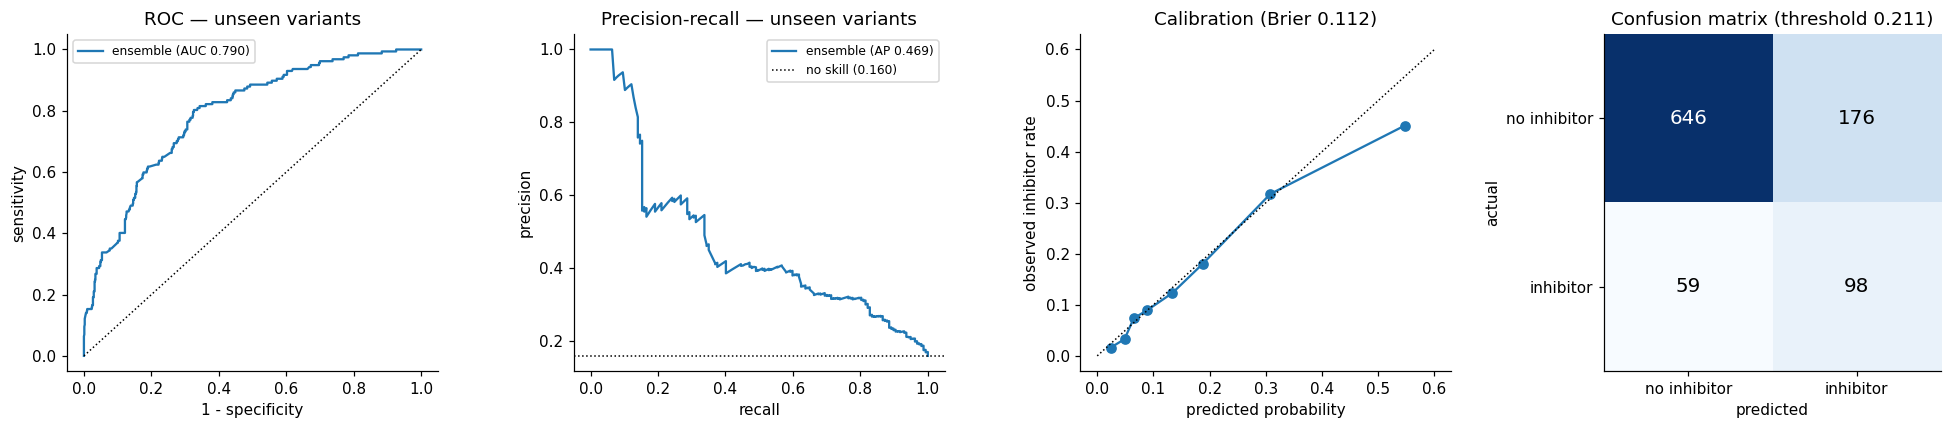

In [6]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
fpr, tpr, _ = roc_curve(y_te, p_te); pr, rc, _ = precision_recall_curve(y_te, p_te)
ax[0].plot(fpr, tpr, c="#1f77b4", label=f"ensemble (AUC {m['ROC-AUC']:.3f})"); ax[0].plot([0, 1], [0, 1], "k:", lw=1)
ax[0].set(xlabel="1 - specificity", ylabel="sensitivity", title="ROC — unseen variants"); ax[0].legend(fontsize=8)
ax[1].plot(rc, pr, c="#1f77b4", label=f"ensemble (AP {m['PR-AUC']:.3f})")
ax[1].axhline(y_te.mean(), c="k", ls=":", lw=1, label=f"no skill ({y_te.mean():.3f})")
ax[1].set(xlabel="recall", ylabel="precision", title="Precision-recall — unseen variants"); ax[1].legend(fontsize=8)
frac, mean_p = calibration_curve(y_te, p_te, n_bins=8, strategy="quantile")
ax[2].plot(mean_p, frac, "o-", c="#1f77b4"); ax[2].plot([0, 0.6], [0, 0.6], "k:", lw=1)
ax[2].set(xlabel="predicted probability", ylabel="observed inhibitor rate", title=f"Calibration (Brier {m['Brier']:.3f})")
cm = confusion_matrix(y_te, pred_te)
ax[3].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    ax[3].text(j, i, v, ha="center", va="center", fontsize=13, color="white" if v > cm.max() / 2 else "black")
ax[3].set(xticks=[0, 1], yticks=[0, 1], xticklabels=["no inhibitor", "inhibitor"],
          yticklabels=["no inhibitor", "inhibitor"], xlabel="predicted", ylabel="actual",
          title=f"Confusion matrix (threshold {THR:.3f})")
plt.tight_layout(); save("01_holdout_performance"); plt.show()

**Reading the held-out result.** On 979 reports of 505 variants the model never saw, ROC-AUC is **0.790** and PR-AUC
**0.469** — almost three times the no-skill PR-AUC of 0.160. At the inner-CV threshold the model catches **62 %** of
inhibitor patients (sensitivity) while clearing 79 % of the others. Accuracy (0.760) is *below* the 0.840 a model that
always says "no inhibitor" would score; that is expected and correct, because the threshold is set to find inhibitor
patients (MCC), not to maximise accuracy — the "always no" model finds none of them. The calibration curve follows the
diagonal (Brier 0.112), so a predicted 30 % really does mean roughly 30 % of such patients develop inhibitors.
These numbers match notebook 02, Section 6.1 exactly, so the explanations below are of the evaluated model. The
interval widths (e.g. AUC 0.739–0.835) are why notebook 02's 25-fold repeated CV (0.768) is the headline figure.

## 3. SHAP — explaining the whole ensemble

**What a SHAP value is.** For one patient, the SHAP value of an input is how much that input moves the predicted
probability away from the average prediction (the *base value*), averaged fairly over all orders in which inputs
could be revealed (Lundberg & Lee 2017). The values of all inputs add up exactly to *prediction − base value*.

**How it is computed here.**
* Each of the four tree models is explained with **exact interventional TreeSHAP in probability space**, against the
  same background of 100 random training reports.
* Each model sees encoded columns (one-hot categories, missing-value indicators for the random forest); their SHAP
  values are **summed back to the 51 raw inputs**.
* The ensemble predicts the *mean* of the four probabilities. Shapley values are linear in the model, so **the mean of
  the four SHAP vectors is the exact SHAP explanation of the ensemble** — not an approximation and not a surrogate model.

The first check is that the explanation adds up to the model's actual output for every held-out patient.

In [7]:
t = time.time()
background = X_tr.sample(100, random_state=0)
explainer = EnsembleShap(model, background)
E = explainer(X_te)
print(f"SHAP for {len(X_te)} held-out reports in {time.time() - t:.0f} s | base value (mean prediction on background) "
      f"= {explainer.base_value:.4f}")

each_p = model.predict_each(X_te)
gap = {n: np.abs(explainer.base_each[n] + v.sum(1) - each_p[n]) for n, v in E.each.items()}
gap["ENSEMBLE"] = np.abs(E.base_values + E.values.sum(1) - p_te)
add = pd.DataFrame({n: {"mean": g.mean(), "99th percentile": np.quantile(g, 0.99), "max": g.max(),
                        "patients within 0.001": f"{(g <= 1e-3).mean():.1%}"} for n, g in gap.items()}).T
display(Markdown("**|base value + sum of SHAP values - predicted probability|, per held-out patient**"))
display(add.assign(**{c: add[c].map(lambda v: f"{v:.1e}") for c in ["mean", "99th percentile", "max"]}))
SV = pd.DataFrame(E.values, columns=E.feature_names, index=X_te.index)
SV.assign(predicted=p_te, actual=y_te).to_csv(TAB / "shap_values_heldout.csv")

SHAP for 979 held-out reports in 153 s | base value (mean prediction on background) = 0.1370


**|base value + sum of SHAP values - predicted probability|, per held-out patient**

,mean,99th percentile,max,patients within 0.001
LightGBM,8.5e-05,2.3e-03,5.0e-03,97.5%
XGBoost,5.3e-08,1.8e-07,3.1e-07,100.0%
CatBoost,1.4e-09,4.9e-09,7.0e-09,100.0%
Random forest,1.7e-04,2.5e-03,5.6e-02,96.3%
ENSEMBLE,6.1e-05,8.7e-04,1.4e-02,99.2%


For XGBoost and CatBoost the SHAP values reproduce the prediction to 10⁻⁷ or better. LightGBM and the random forest
show small residuals on a handful of patients (mean ≈ 10⁻⁴; well over 95 % of patients within 0.001), a known numerical
effect of evaluating very deep or many-tree models against a background set — not an approximation in the method. For
interpretation purposes the ensemble explanation adds up to its prediction.

### 3.1 Global importance — which inputs drive the predictions

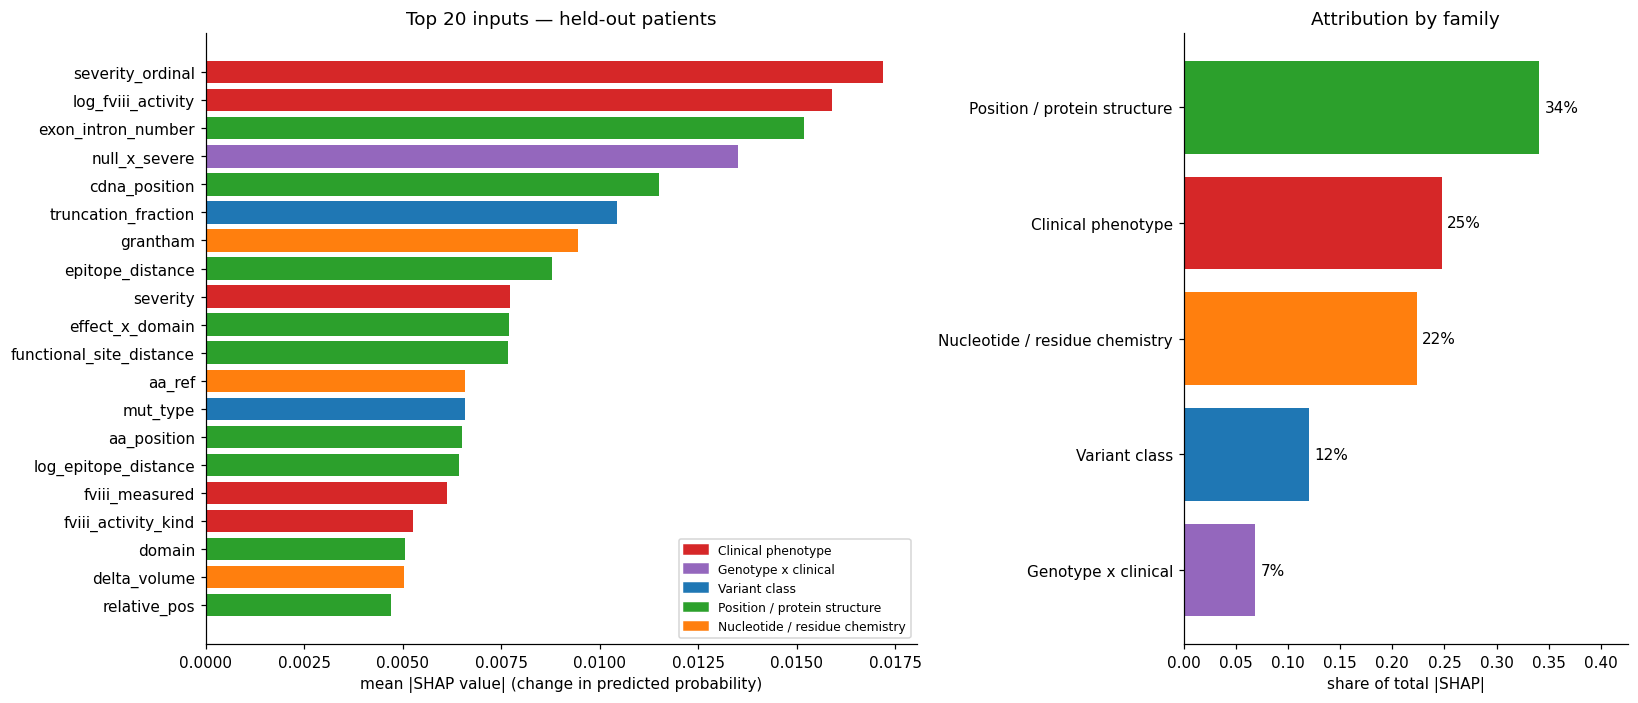

Genomic families: 68.4% | clinical phenotype: 24.7% | genotype x clinical interactions: 6.8%


In [8]:
imp = SV.abs().mean().sort_values(ascending=False)
fam_imp = imp.groupby(imp.index.map(FAM_OF)).sum().sort_values(ascending=False)
fam_share = fam_imp / fam_imp.sum()

fig, ax = plt.subplots(1, 2, figsize=(15, 6.5), gridspec_kw={"width_ratios": [1.6, 1]})
top = imp.head(20)[::-1]
ax[0].barh(top.index, top.values, color=[FAM_COLOR[FAM_OF[f]] for f in top.index])
ax[0].set(xlabel="mean |SHAP value| (change in predicted probability)", title="Top 20 inputs — held-out patients")
from matplotlib.patches import Patch
ax[0].legend(handles=[Patch(color=c, label=f) for f, c in FAM_COLOR.items()], fontsize=8, loc="lower right")
ax[1].barh(fam_share.index[::-1], fam_share.values[::-1], color=[FAM_COLOR[f] for f in fam_share.index[::-1]])
for i, v in enumerate(fam_share.values[::-1]):
    ax[1].text(v + 0.005, i, f"{v:.0%}", va="center")
ax[1].set(xlabel="share of total |SHAP|", title="Attribution by family", xlim=(0, fam_share.max() * 1.25))
plt.tight_layout(); save("02_shap_global_importance"); plt.show()

genomic_share = fam_share[fam_share.index.isin(GENOMIC)].sum()
print(f"Genomic families: {genomic_share:.1%} | clinical phenotype: {fam_share['Clinical phenotype']:.1%} | "
      f"genotype x clinical interactions: {fam_share['Genotype x clinical']:.1%}")
pd.DataFrame({"mean_abs_shap": imp, "family": imp.index.map(FAM_OF),
              "description": imp.index.map(lambda f: DESCRIPTION.get(f, ""))}).to_csv(TAB / "shap_global_importance.csv")
fam_share.rename("share").to_csv(TAB / "shap_family_share.csv")

**What drives the predictions.** The two strongest single inputs are clinical — **severity** and **residual FVIII
activity** — followed by where the variant lies (exon, cDNA position, distance to the inhibitor epitopes) and the
**null-variant × severe** interaction. By family, **genomic information carries about two-thirds of the attribution
(68 %) and the patient's clinical phenotype a quarter (25 %)**, with a further 7 % in genotype × clinical interactions.
Neither block alone tells the story — this is the quantitative case for *fusing* genomic and clinical data, which is the
premise of the project title. Several of the strongest inputs (null × severe, truncation fraction, epitope distance,
Grantham distance) are among the 26 biology features added in notebook 02.

### 3.2 Direction of the effects (beeswarm)

Each dot is one held-out patient. Position = SHAP value (right = pushes towards inhibitor); colour = the input's value
(red high, blue low). Categorical inputs have no numeric scale and are drawn grey.

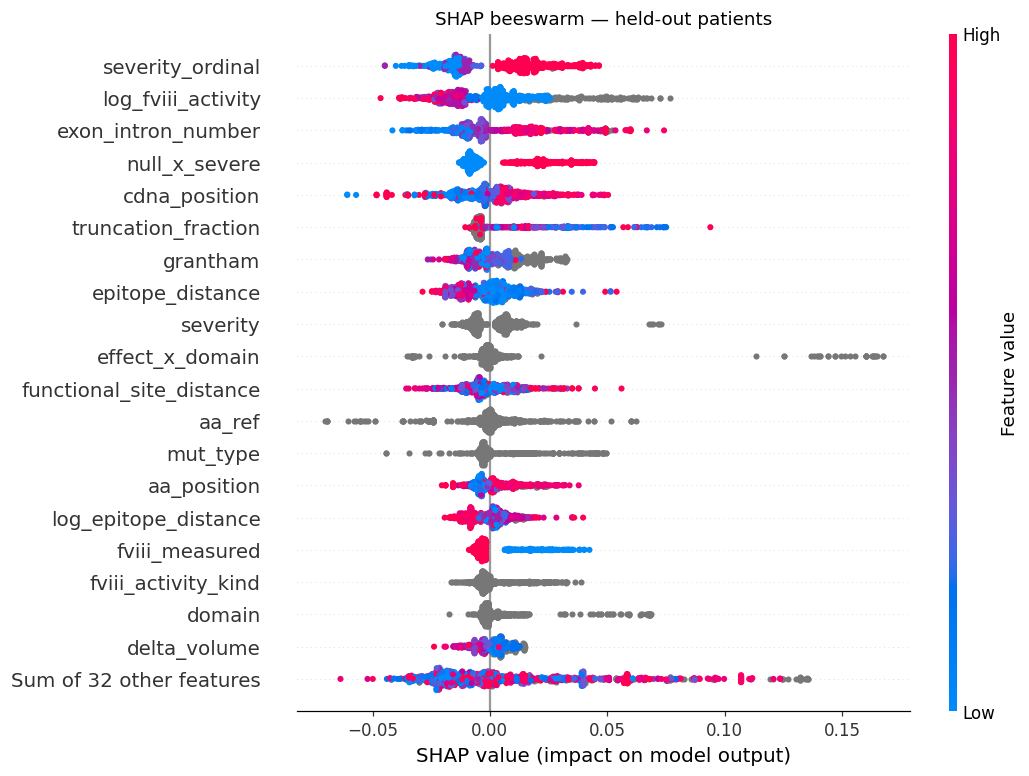

In [9]:
shap.plots.beeswarm(E, max_display=20, show=False, plot_size=(9, 8))
plt.title("SHAP beeswarm — held-out patients"); save("03_shap_beeswarm"); plt.show()

The colour pattern gives direction: **high severity** (red) pushes right (more risk) and **high FVIII activity** pushes
left (less risk); `null_x_severe = 1` and a large `truncation_fraction` push right. For position-type inputs the effect
is not monotonic — risk depends on *which* region of the protein is hit, which the next section examines.

### 3.3 Does the model follow the known biology?

The literature gives clear expectations for inhibitor risk in haemophilia A: **null variants** (large deletions,
nonsense, frameshift — no endogenous FVIII, so no immune tolerance) carry the highest risk; **severe** disease carries
more risk than mild/moderate; **low residual FVIII activity** carries more risk; among missense variants, those in the
**A2 and C1/C2 domains** (the main inhibitor epitopes) carry more risk (Gouw 2012; Eckhardt 2013; Oldenburg 2004).
The model was never told any of this. If its SHAP values reproduce these directions, it has learnt biology, not noise.

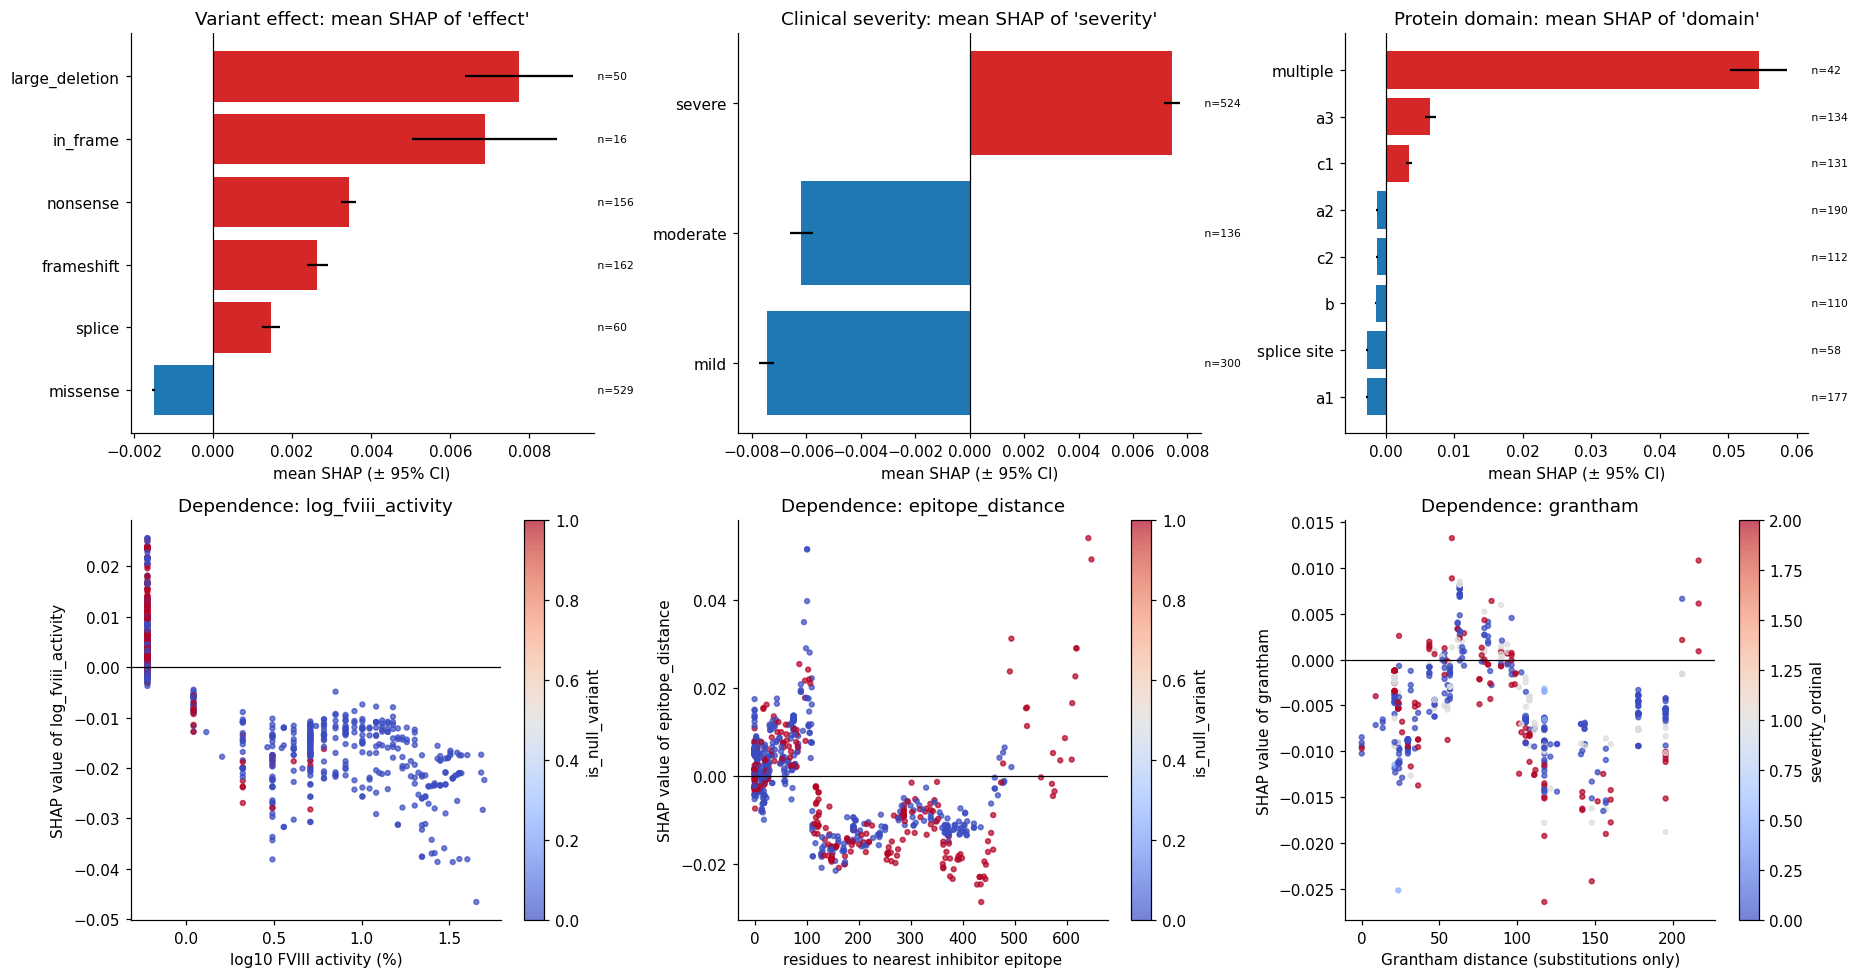

,measured as,model (held-out SHAP),agrees
literature expectation,,,
Null variants raise risk (Gouw 2012),"mean variant-class SHAP, null vs other",+0.039 vs -0.012,True
Large deletions highest of all effects,rank of large_deletion among effects by mean SHAP,1 of 6,True
Severe > moderate > mild,mean SHAP of 'severity',mild -0.007 / moderate -0.006 / severe +0.007,True
Lower FVIII activity raises risk,"Spearman(activity, its SHAP)",-0.85,True
Missense in A2/C1/C2 riskier than elsewhere (Eckhardt 2013),"mean domain SHAP of missense, A2/C1/C2 vs other",+0.0009 vs -0.0018,True


In [10]:
def mean_shap_by(col, values=None, min_n=15):
    d = pd.DataFrame({"category": X_te[col].astype(str).values, "shap": SV[col].values})
    g = d.groupby("category")["shap"].agg(["mean", "count", "sem"])
    g = g[g["count"] >= min_n]
    return g.loc[[v for v in values if v in g.index]] if values else g.sort_values("mean")

fig, ax = plt.subplots(2, 3, figsize=(17, 9))
for a, (col, vals, title) in zip(ax[0], [
        ("effect", None, "Variant effect"),
        ("severity", ["mild", "moderate", "severe"], "Clinical severity"),
        ("domain", None, "Protein domain")]):
    g = mean_shap_by(col, vals)
    a.barh(g.index, g["mean"], xerr=1.96 * g["sem"].fillna(0), color=np.where(g["mean"] > 0, "#d62728", "#1f77b4"))
    a.axvline(0, c="k", lw=0.8); a.set(title=f"{title}: mean SHAP of '{col}'", xlabel="mean SHAP (± 95% CI)")
    for i, n in enumerate(g["count"]):
        a.text(a.get_xlim()[1], i, f" n={n}", va="center", fontsize=7)

for a, (col, color_by, label) in zip(ax[1], [
        ("log_fviii_activity", "is_null_variant", "log10 FVIII activity (%)"),
        ("epitope_distance", "is_null_variant", "residues to nearest inhibitor epitope"),
        ("grantham", "severity_ordinal", "Grantham distance (substitutions only)")]):
    v = X_te[col].to_numpy(dtype=float); ok = ~np.isnan(v)
    sc = a.scatter(v[ok], SV[col].values[ok], c=X_te[color_by].to_numpy(dtype=float)[ok], cmap="coolwarm", s=10, alpha=0.7)
    a.axhline(0, c="k", lw=0.8); a.set(xlabel=label, ylabel=f"SHAP value of {col}", title=f"Dependence: {col}")
    plt.colorbar(sc, ax=a, label=color_by)
plt.tight_layout(); save("04_shap_biology_check"); plt.show()

# literature expectations vs. what the model learnt (all computed on held-out patients)
eff, sev, dom = mean_shap_by("effect"), mean_shap_by("severity"), mean_shap_by("domain")
null_eff = [e for e in ["large_deletion", "nonsense", "frameshift"] if e in eff.index]
miss = X_te["effect"].eq("missense").to_numpy()
miss_dom = pd.DataFrame({"d": X_te["domain"].values[miss], "s": SV["domain"].values[miss] + SV["effect_x_domain"].values[miss]})
hot = miss_dom["d"].isin(["a2", "c1", "c2"])
act = X_te["log_fviii_activity"].to_numpy(dtype=float); okA = ~np.isnan(act)
rho_act = spearmanr(act[okA], SV["log_fviii_activity"].values[okA])[0]
null_pts = X_te["is_null_variant"].eq(1).to_numpy()
vtype_total = SV[[c for c in FAMILY["Variant class"]]].sum(1).to_numpy()
checks = pd.DataFrame([
    ["Null variants raise risk (Gouw 2012)", "mean variant-class SHAP, null vs other",
     f"{vtype_total[null_pts].mean():+.3f} vs {vtype_total[~null_pts].mean():+.3f}",
     vtype_total[null_pts].mean() > vtype_total[~null_pts].mean()],
    ["Large deletions highest of all effects", "rank of large_deletion among effects by mean SHAP",
     f"{list(eff.sort_values('mean', ascending=False).index).index('large_deletion') + 1} of {len(eff)}" if "large_deletion" in eff.index else "n/a",
     "large_deletion" in eff.index and eff["mean"].idxmax() in null_eff],
    ["Severe > moderate > mild", "mean SHAP of 'severity'",
     " / ".join(f"{k} {sev.loc[k, 'mean']:+.3f}" for k in ["mild", "moderate", "severe"] if k in sev.index),
     all(k in sev.index for k in ["mild", "severe"]) and sev.loc["severe", "mean"] > sev.loc["mild", "mean"]],
    ["Lower FVIII activity raises risk", "Spearman(activity, its SHAP)", f"{rho_act:+.2f}", rho_act < 0],
    ["Missense in A2/C1/C2 riskier than elsewhere (Eckhardt 2013)", "mean domain SHAP of missense, A2/C1/C2 vs other",
     f"{miss_dom.loc[hot, 's'].mean():+.4f} vs {miss_dom.loc[~hot, 's'].mean():+.4f}",
     miss_dom.loc[hot, "s"].mean() > miss_dom.loc[~hot, "s"].mean()],
], columns=["literature expectation", "measured as", "model (held-out SHAP)", "agrees"]).set_index("literature expectation")
checks.to_csv(TAB / "shap_biology_checks.csv")
display(checks)

**All five literature expectations are reproduced** — and the model was never told any of them:

* **Variant effect:** large deletions carry the highest mean SHAP of all effects, followed by nonsense and frameshift
  (the null variants); missense variants lower the predicted risk. This is the ranking reported by Gouw et al. 2012.
* **Severity:** severe raises risk, mild and moderate lower it.
* **Residual FVIII activity:** strongly monotonic (Spearman −0.85) — patients with < 1 % activity are pushed up, and the
  more FVIII a patient makes, the lower the risk. Endogenous FVIII induces immune tolerance.
* **Domain:** variants spanning **multiple domains** (mostly large deletions) dominate; among missense variants, those
  in the epitope-bearing A2/C1/C2 domains score above the others, although that effect is small.
* **Epitope distance:** variants within ~100 residues of a known inhibitor epitope raise risk, those far away lower it.

A model that matched the data by noise would not line up with independent clinical knowledge like this; this is the
strongest evidence that the model has learnt real biology.

### 3.4 Do the four models explain the predictions the same way?

If the ensemble members relied on different inputs, the averaged explanation would hide disagreement. The table
compares each model's global SHAP ranking with the others (Spearman correlation over the 51 inputs).

In [11]:
imp_each = pd.DataFrame({n: np.abs(v).mean(0) for n, v in E.each.items()}, index=E.feature_names)
rho = imp_each.corr(method="spearman")
top10 = {n: set(imp_each[n].nlargest(10).index) for n in imp_each}
overlap = pd.DataFrame({a: {b: len(top10[a] & top10[b]) for b in top10} for a in top10})
display(Markdown("**Spearman correlation of global importance between models**")); display(rho.round(2))
display(Markdown("**Shared inputs in each pair's top 10**")); display(overlap)
print("Inputs in the top 10 of all four models:", sorted(set.intersection(*top10.values())))

**Spearman correlation of global importance between models**

,LightGBM,XGBoost,CatBoost,Random forest
LightGBM,1.00,0.97,0.78,0.84
XGBoost,0.97,1.00,0.78,0.85
CatBoost,0.78,0.78,1.00,0.90
Random forest,0.84,0.85,0.90,1.00


**Shared inputs in each pair's top 10**

,LightGBM,XGBoost,CatBoost,Random forest
LightGBM,10,9,5,7
XGBoost,9,10,6,8
CatBoost,5,6,10,6
Random forest,7,8,6,10


Inputs in the top 10 of all four models: ['cdna_position', 'exon_intron_number', 'log_fviii_activity', 'severity_ordinal', 'truncation_fraction']


The four models agree closely on what matters (Spearman 0.78–0.97; LightGBM and XGBoost almost identical), and five
inputs — **cDNA position, exon number, FVIII activity, severity and truncation fraction** — are in the top 10 of every
model. The averaged explanation therefore summarises a genuine consensus, not four different stories.

## 4. SHAP for individual patients

Four held-out patients, chosen by rule (not by hand) to show the full range of behaviour:

* **A — correct high-risk call:** the inhibitor patient with the highest predicted risk.
* **B — correct low-risk call:** the non-inhibitor patient with the lowest predicted risk.
* **C — missed inhibitor:** the inhibitor patient with the lowest predicted risk.
* **D — false alarm:** the non-inhibitor patient with the highest predicted risk.

A waterfall plot starts at the base value (average risk) and adds each input's SHAP value until it reaches the
patient's predicted probability.

,A: correct high-risk,B: correct low-risk,C: missed inhibitor,D: false alarm
cDNA variant,NULL,c.398A>G,c.787+143T>C,c.788-?_7056+?del
protein change,NULL,p.Tyr133Cys,NULL,NULL
effect,Large Deletion,Missense,Splice,Large Deletion
domain,Multiple Domains,A1,Splice Site,Multiple Domains
severity,Severe,Mild,Moderate,Severe
FVIII activity (%),<1,11,1 to 5,<1
actual inhibitor,yes,no,yes,no
predicted probability,0.854,0.01,0.025,0.823
flagged (>= threshold),yes,no,no,yes


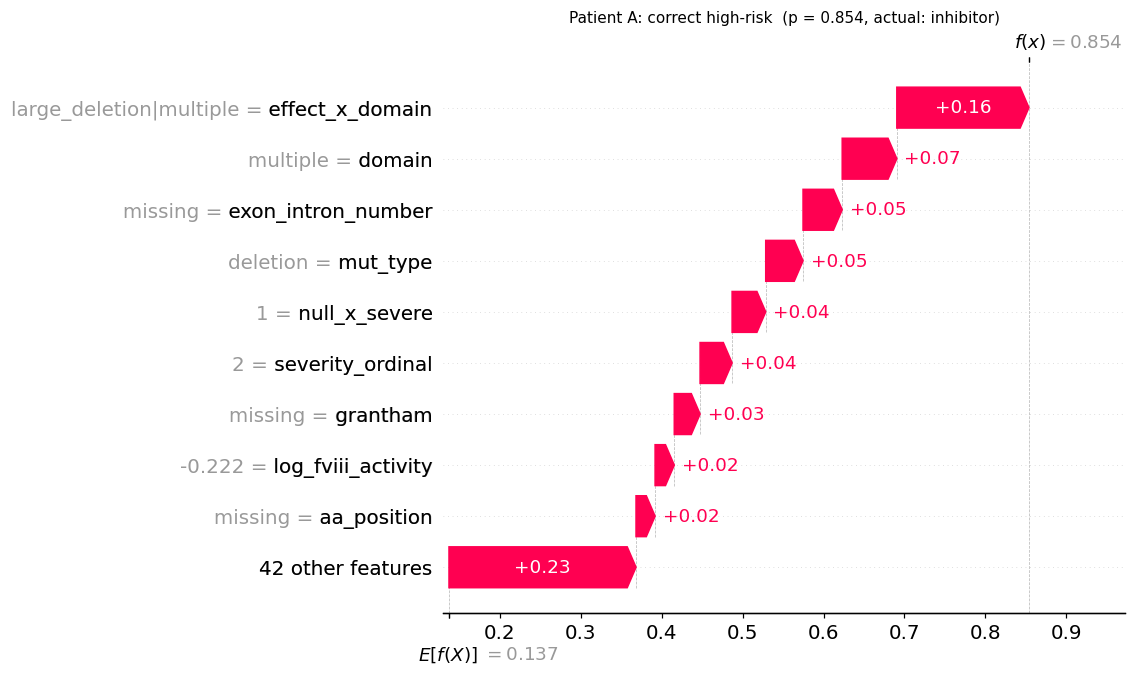

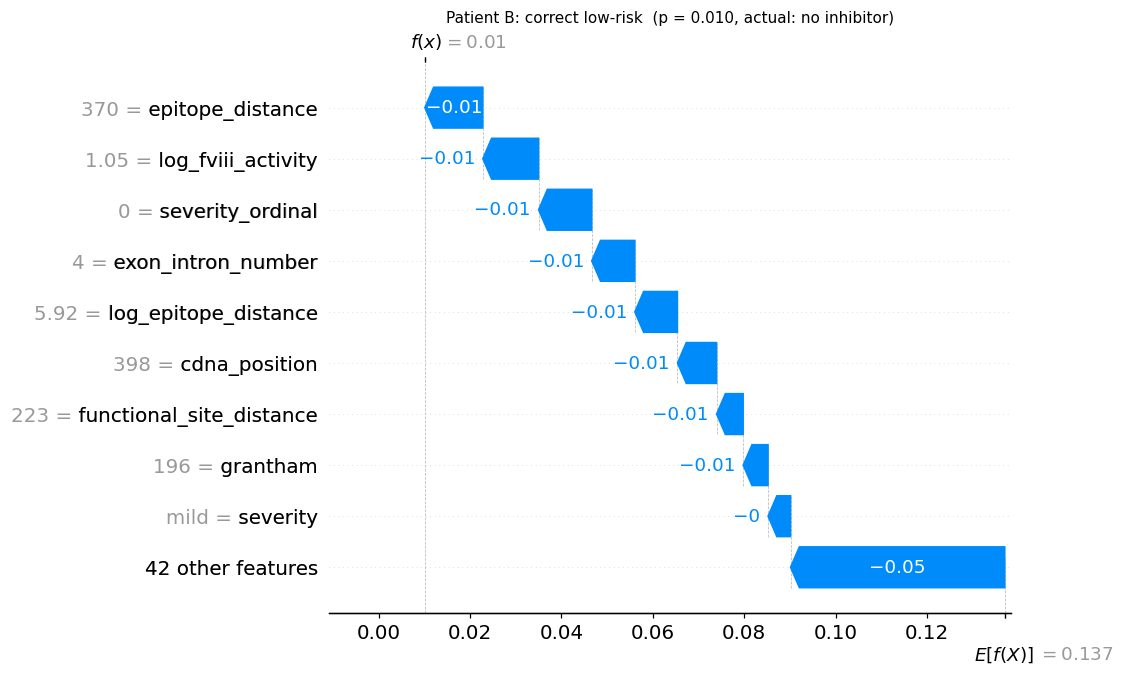

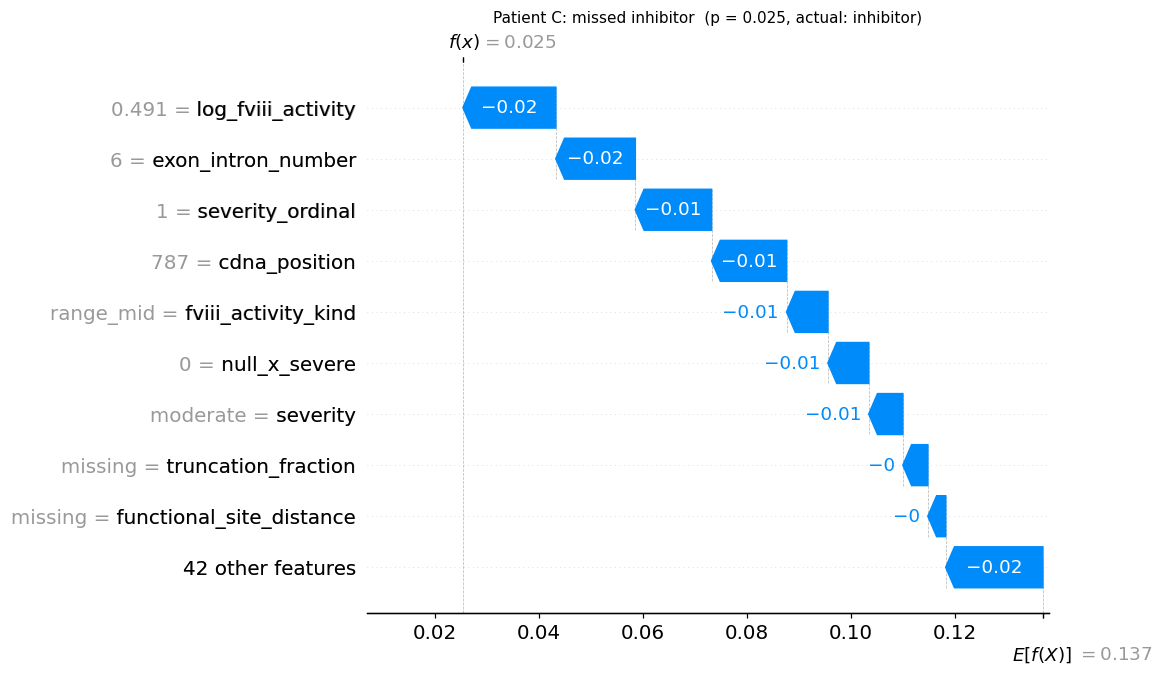

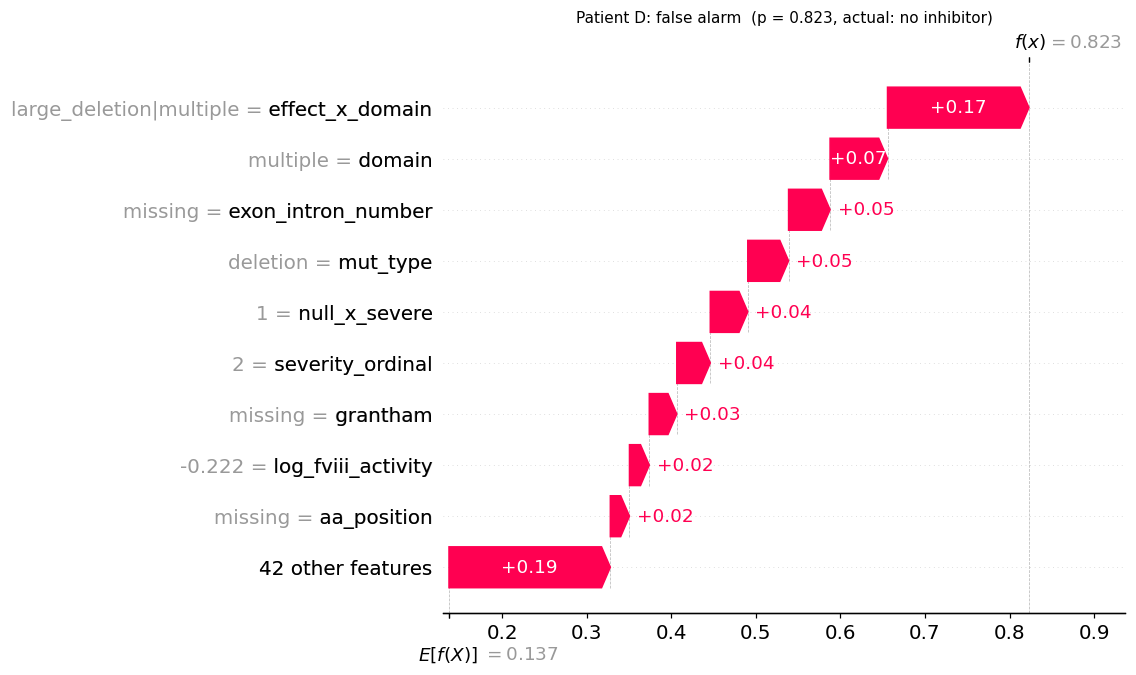

In [12]:
pos_te = np.arange(len(te))
CASES = {
    "A: correct high-risk": pos_te[y_te == 1][np.argmax(p_te[y_te == 1])],
    "B: correct low-risk": pos_te[y_te == 0][np.argmin(p_te[y_te == 0])],
    "C: missed inhibitor": pos_te[y_te == 1][np.argmin(p_te[y_te == 1])],
    "D: false alarm": pos_te[y_te == 0][np.argmax(p_te[y_te == 0])],
}
show_cols = {"mut_syn": "cDNA variant", "aa_syn": "protein change", "mut_effect": "effect", "d_id": "domain",
             "cli_phe": "severity", "clotting": "FVIII activity (%)"}
case_table = pd.DataFrame({k: {**{lab: df.iloc[te[i]][c] for c, lab in show_cols.items()},
                               "actual inhibitor": "yes" if y_te[i] else "no",
                               "predicted probability": round(float(p_te[i]), 3),
                               "flagged (>= threshold)": "yes" if p_te[i] >= THR else "no"} for k, i in CASES.items()})
display(case_table)
for k, i in CASES.items():
    shap.plots.waterfall(row_explanation(E, i), max_display=10, show=False)
    plt.title(f"Patient {k}  (p = {p_te[i]:.3f}, actual: {'inhibitor' if y_te[i] else 'no inhibitor'})", fontsize=10)
    save(f"05_shap_waterfall_{k[0]}"); plt.show()

**What the four patients show.**

* **A (correct, p = 0.85):** a large deletion spanning several domains in a severe patient with < 1 % FVIII. The
  explanation is exactly the textbook high-risk profile: deletion × multiple domains, null × severe, severity, no FVIII.
* **B (correct, p = 0.01):** a mild missense variant (p.Tyr133Cys, A1 domain) with 11 % FVIII, far (370 residues) from
  any inhibitor epitope. Every top input lowers the risk.
* **C (missed, p = 0.03):** a splice variant in a moderate patient with 1–5 % FVIII. On genotype and phenotype this is a
  low-risk patient, and the model says so. The inhibitor almost certainly came from something the data do not record —
  treatment intensity, surgery, product type or immune genetics. This is the limitation in one patient.
* **D (false alarm, p = 0.82):** has *the same profile as A* (large multi-domain deletion, severe, < 1 % FVIII) but did
  not develop an inhibitor. Patients A and D are indistinguishable with the available inputs, so no model could
  separate them: about 12 % of reports share their exact inputs with a report of the opposite outcome (notebook 02,
  Section 5). This is irreducible error for this dataset, not a model defect. Clinically, D is the right patient to
  monitor closely even though they were lucky.

## 5. LIME

**What LIME does.** LIME (Ribeiro et al. 2016) explains one prediction by generating thousands of perturbed versions
of the patient, scoring them with the model, and fitting a small weighted linear model around the patient. Its
weights say which of the patient's input values, if changed, would change the prediction most.

**How it is set up here.**
* Every numeric input is binned at the training quartiles, **plus an explicit "missing" bin** (many inputs, such as
  the Grantham distance, only exist for some variant types). A perturbed patient therefore only ever takes values that
  real training patients have; a missing value is never replaced by an invented number the trees would misread.
* Categorical inputs are perturbed by drawing categories at their training frequencies.
* 5,000 perturbations per patient; the default exponential kernel (width 0.75·√51).
* The explanation is of the **same model and the same patients** as the SHAP section.

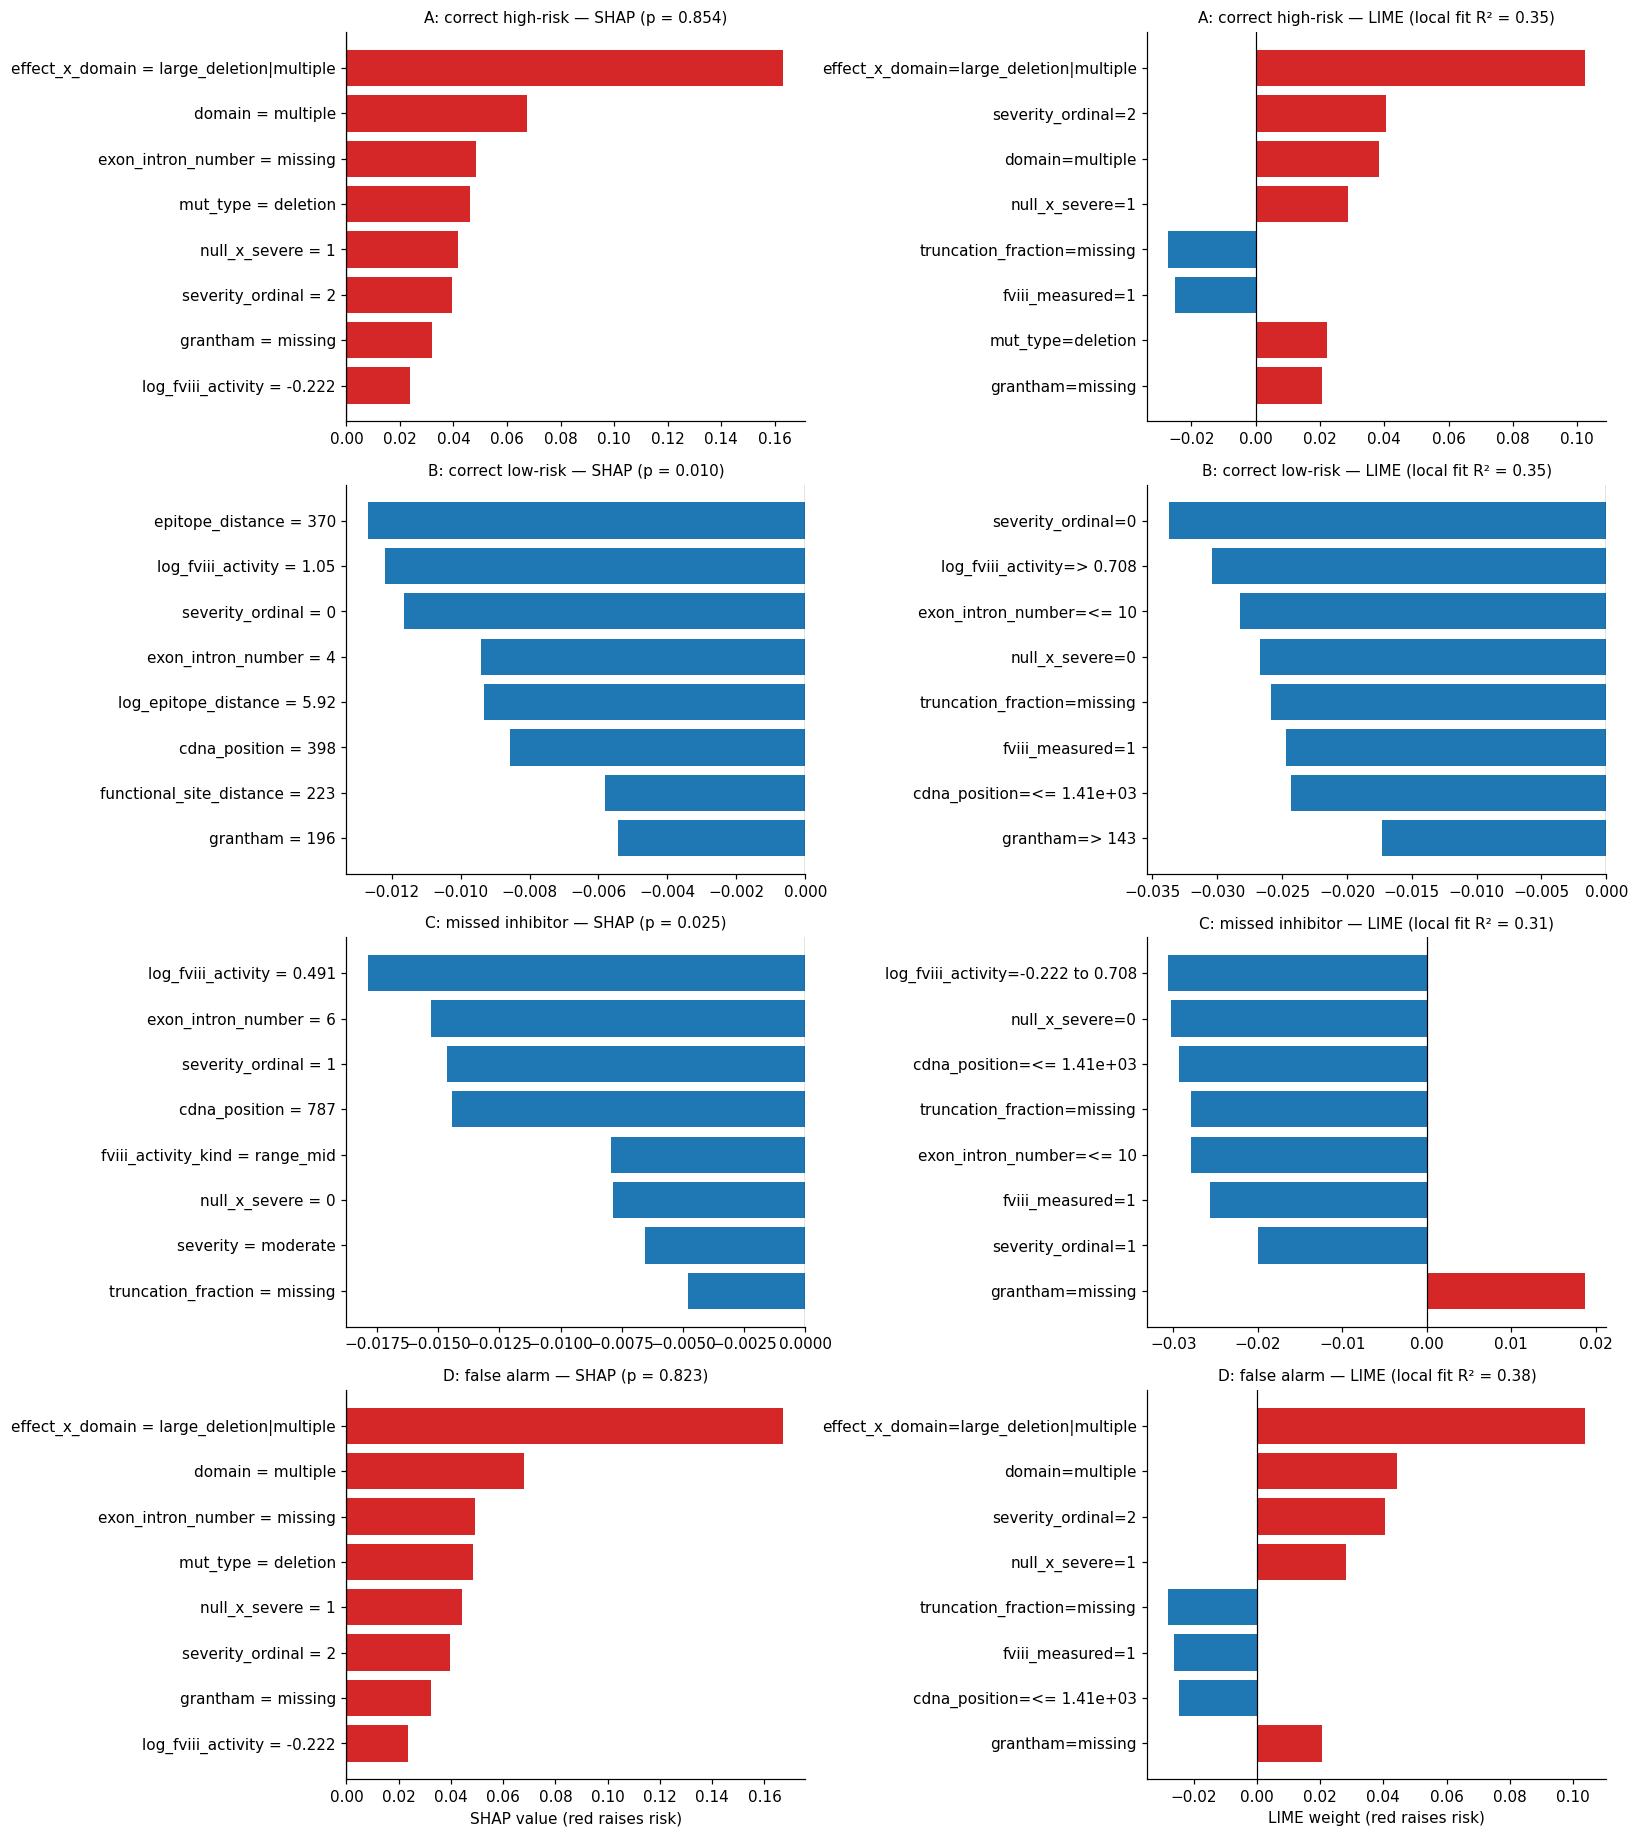

,model p,LIME local prediction,LIME fit R²,SHAP top-5,LIME top-5,shared in top-5
patient,,,,,,
A: correct high-risk,0.854,0.359,0.348,"effect_x_domain, domain, exon_intron_number, m...","effect_x_domain, severity_ordinal, domain, nul...",3
B: correct low-risk,0.010,0.012,0.353,"epitope_distance, log_fviii_activity, severity...","severity_ordinal, log_fviii_activity, exon_int...",3
C: missed inhibitor,0.025,0.039,0.306,"log_fviii_activity, exon_intron_number, severi...","log_fviii_activity, null_x_severe, cdna_positi...",3
D: false alarm,0.823,0.345,0.376,"effect_x_domain, domain, exon_intron_number, m...","effect_x_domain, domain, severity_ordinal, nul...",3


In [13]:
lime_view = LimeView(model, X_tr, X)
LIME = {}
for k, i in CASES.items():
    LIME[k] = lime_view.explain(X_te.iloc[[i]], num_features=10, num_samples=5000, seed=0)

fig, ax = plt.subplots(len(CASES), 2, figsize=(15, 4.2 * len(CASES)))
for r, (k, i) in enumerate(CASES.items()):
    s = SV.iloc[i]; s = s[s.abs().sort_values(ascending=False).index[:8]][::-1]
    fmt = lambda v: "missing" if pd.isna(v) else (f"{v:.3g}" if isinstance(v, (float, np.floating)) else str(v))
    ax[r, 0].barh([f"{f} = {fmt(X_te.iloc[i][f])}"[:48] for f in s.index],
                  s.values, color=np.where(s.values > 0, "#d62728", "#1f77b4"))
    ax[r, 0].axvline(0, c="k", lw=0.8); ax[r, 0].set_title(f"{k} — SHAP (p = {p_te[i]:.3f})", fontsize=10)
    lst = LIME[k].as_list(label=1)[:8][::-1]
    ax[r, 1].barh([n[:48] for n, _ in lst], [w for _, w in lst],
                  color=["#d62728" if w > 0 else "#1f77b4" for _, w in lst])
    ax[r, 1].axvline(0, c="k", lw=0.8)
    ax[r, 1].set_title(f"{k} — LIME (local fit R² = {LIME[k].score:.2f})", fontsize=10)
ax[-1, 0].set_xlabel("SHAP value (red raises risk)"); ax[-1, 1].set_xlabel("LIME weight (red raises risk)")
plt.tight_layout(); save("06_shap_vs_lime_cases"); plt.show()

rows = []
for k, i in CASES.items():
    w = lime_view.weights(LIME[k]); s = SV.iloc[i]
    rows.append({"patient": k, "model p": p_te[i], "LIME local prediction": float(np.ravel(LIME[k].local_pred)[0]),
                 "LIME fit R²": LIME[k].score,
                 "SHAP top-5": ", ".join(s.abs().nlargest(5).index),
                 "LIME top-5": ", ".join(w.abs().nlargest(5).index),
                 "shared in top-5": len(set(s.abs().nlargest(5).index) & set(w.abs().nlargest(5).index))})
display(pd.DataFrame(rows).set_index("patient"))

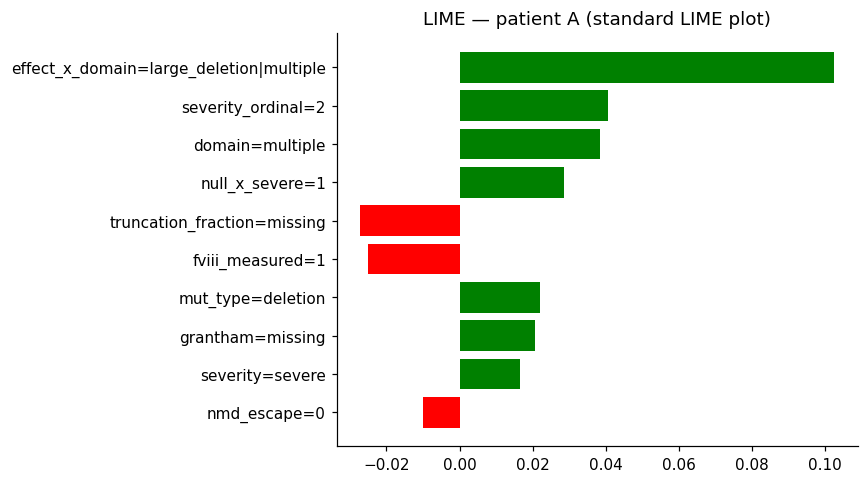

In [14]:
fig = LIME["A: correct high-risk"].as_pyplot_figure(label=1)
fig.set_size_inches(8, 4.5); plt.title("LIME — patient A (standard LIME plot)"); plt.tight_layout()
save("07_lime_patient_A"); plt.show()

**LIME on the same patients.** For every patient LIME shares 3 of SHAP's top 5 inputs and agrees on their direction —
for A and D the large multi-domain deletion, null × severe and severity; for B and C the high FVIII activity and the
absence of a severe null genotype. The differences are instructive: LIME's local linear fit explains only about a
third of the model's behaviour near each patient (R² 0.31–0.38) and under-shoots the extreme predictions (local
prediction 0.36 for patient A against the model's 0.85), because a straight line cannot follow the trees' sharp
interactions. LIME also gives `truncation_fraction = missing` a negative weight for deletions, which reflects how the
perturbation was sampled rather than biology. SHAP has neither problem, so it is the primary explanation.

### 5.1 Do SHAP and LIME agree? (100 held-out patients)

Two methods built on different principles (game-theoretic attribution vs. a local surrogate) should point to broadly
the same inputs if the explanations are real. For 100 randomly drawn held-out patients, LIME is run with all 51 inputs
and compared with SHAP:

* **Top-5 overlap** — how many of SHAP's 5 most important inputs are also in LIME's 5. Chance level is 5·5/51 ≈ 0.5.
* **Rank correlation** — Spearman correlation of |attribution| over all 51 inputs.
* **Sign agreement** — for SHAP's top-5 inputs, how often LIME gives the same direction (raises / lowers risk).

,value
mean top-5 overlap (of 5),2.750
chance-level top-5 overlap,0.490
share of patients with >= 3 shared,0.660
mean Spearman of |attribution| (51 inputs),0.585
sign agreement on SHAP's top 5,0.996


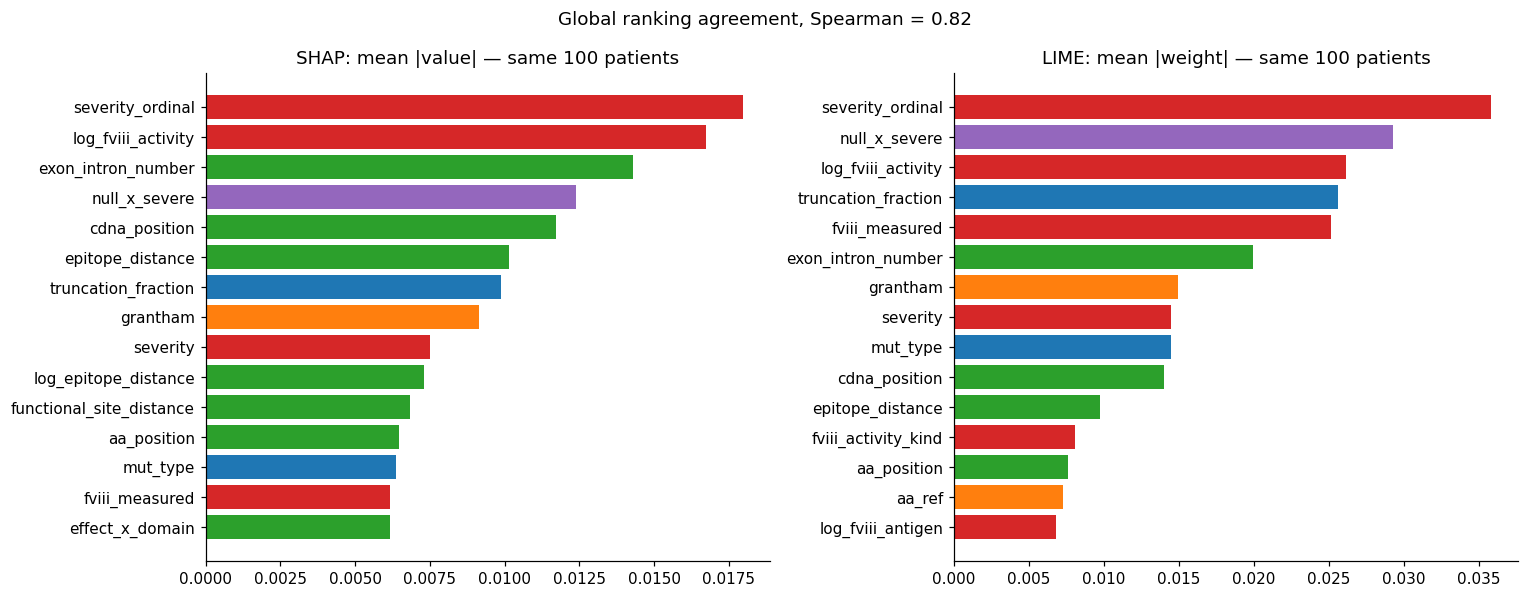

LIME on 100 patients: 49 s | top-10 inputs shared globally: 8 of 10


In [15]:
t = time.time()
sample = np.random.default_rng(1).choice(len(te), 100, replace=False)
LW = {}
for i in sample:
    LW[i] = lime_view.weights(lime_view.explain(X_te.iloc[[i]], num_features=X.shape[1], num_samples=5000, seed=0))
agree = []
for i in sample:
    s, w = SV.iloc[i], LW[i]
    t5s, t5l = set(s.abs().nlargest(5).index), set(w.abs().nlargest(5).index)
    top_s = s.abs().nlargest(5).index
    agree.append({"top5_overlap": len(t5s & t5l), "spearman_abs": spearmanr(s.abs(), w.abs())[0],
                  "sign_agreement_top5": np.mean(np.sign(s[top_s]) == np.sign(w[top_s])),
                  "y": y_te[i], "p": p_te[i]})
agree = pd.DataFrame(agree, index=sample)
agree.to_csv(TAB / "shap_lime_agreement.csv")
summary_agree = pd.Series({
    "mean top-5 overlap (of 5)": agree["top5_overlap"].mean(), "chance-level top-5 overlap": 25 / 51,
    "share of patients with >= 3 shared": (agree["top5_overlap"] >= 3).mean(),
    "mean Spearman of |attribution| (51 inputs)": agree["spearman_abs"].mean(),
    "sign agreement on SHAP's top 5": agree["sign_agreement_top5"].mean()})
display(summary_agree.round(3).to_frame("value"))

lime_global = pd.DataFrame(LW).T.abs().mean().sort_values(ascending=False)
shap_global = SV.iloc[sample].abs().mean()
rho_g = spearmanr(shap_global[lime_global.index], lime_global)[0]
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for a, s, ttl in [(ax[0], shap_global.sort_values(ascending=False), "SHAP: mean |value|"),
                  (ax[1], lime_global, "LIME: mean |weight|")]:
    s = s.head(15)[::-1]
    a.barh(s.index, s.values, color=[FAM_COLOR[FAM_OF[f]] for f in s.index]); a.set_title(f"{ttl} — same 100 patients")
plt.suptitle(f"Global ranking agreement, Spearman = {rho_g:.2f}"); plt.tight_layout(); save("08_shap_vs_lime_global"); plt.show()
print(f"LIME on 100 patients: {time.time() - t:.0f} s | top-10 inputs shared globally: "
      f"{len(set(shap_global.nlargest(10).index) & set(lime_global.head(10).index))} of 10")

**SHAP and LIME agree well beyond chance.** On average **2.75 of the top 5 inputs are shared** (chance: 0.5), two-thirds
of patients share at least 3, and when both methods name an input they **agree on its direction 99.6 % of the time**.
The rank correlation over all 51 inputs is moderate (0.59) because the two methods spread credit differently over the
many weak inputs — the strong ones they agree on. Globally, 8 of the top 10 inputs are the same (Spearman 0.82).
Two methods built on different principles pointing to the same inputs is the main evidence that the explanations
are real.

### 5.2 Is LIME stable?

LIME is random: it samples perturbations. A trustworthy explanation should not change much when only the random
seed changes. SHAP (TreeSHAP) is exact and deterministic, so its stability is 1 by construction. Twenty held-out
patients are explained five times each, with 1,000 and with 5,000 perturbations; the score is the mean Jaccard overlap
of the top-5 inputs between every pair of runs (1 = identical).

In [16]:
from itertools import combinations
stab_rows = []
for i in sample[:20]:
    for ns in (1000, 5000):
        tops = [set(lime_view.weights(lime_view.explain(X_te.iloc[[i]], num_features=10, num_samples=ns, seed=s))
                    .abs().nlargest(5).index) for s in range(5)]
        jac = [len(a & b) / len(a | b) for a, b in combinations(tops, 2)]
        stab_rows.append({"patient": i, "num_samples": ns, "mean Jaccard top-5": np.mean(jac)})
stab = pd.DataFrame(stab_rows)
stab.to_csv(TAB / "lime_stability.csv", index=False)
display(stab.groupby("num_samples")["mean Jaccard top-5"].agg(["mean", "min"]).round(3)
        .rename(index=lambda n: f"LIME, {n} perturbations").T.assign(**{"SHAP (TreeSHAP)": [1.0, 1.0]}))

num_samples,"LIME, 1000 perturbations","LIME, 5000 perturbations",SHAP (TreeSHAP)
mean,0.643,0.853,1.0
min,0.458,0.700,1.0


With 5,000 perturbations LIME's top 5 is fairly stable (mean Jaccard 0.85; worst patient 0.70); with 1,000 it drops to
0.64 — two runs on the same patient can name noticeably different inputs. This is why LIME is run with 5,000
perturbations here, and why the deterministic SHAP values are used for the report and the application.

## 6. Faithfulness — do the highlighted inputs really drive the prediction?

A plot of importances can look convincing and still be wrong. The **deletion test** measures it directly: for each
of the 100 patients, the *k* inputs ranked highest by an explanation are replaced by the values of 50 background
patients (so their information is removed), and the change in predicted probability is recorded. A faithful
explanation must produce a larger change than removing *k* random inputs.

(SHAP is defined against the same kind of background replacement, so it has a natural advantage here; LIME and random
rankings are the comparison.)

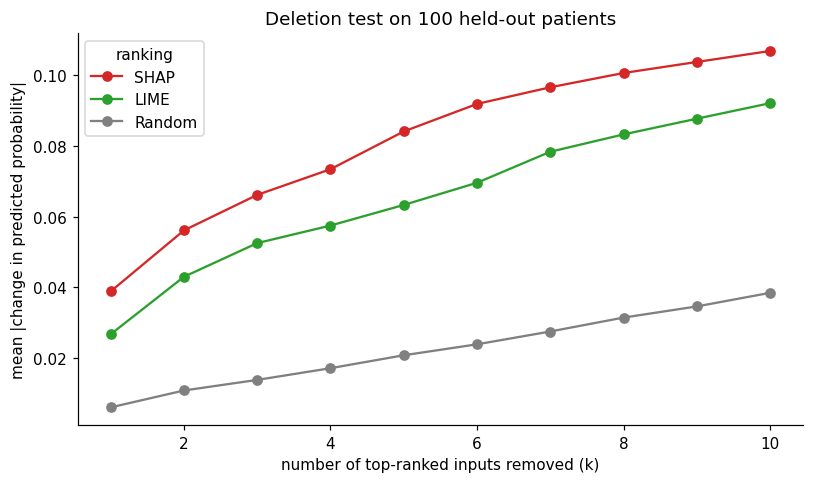

ranking,LIME,Random,SHAP
k,,,
1,0.027,0.006,0.039
3,0.052,0.014,0.066
5,0.063,0.021,0.084
10,0.092,0.038,0.107


47 s


In [17]:
t = time.time()
bg50 = background.sample(50, random_state=1).reset_index(drop=True)
K = list(range(1, 11))
rng = np.random.default_rng(3)
feat = np.array(E.feature_names)
res = []
for i in sample:
    xi = X_te.iloc[i]
    rankings = {"SHAP": SV.iloc[i].abs().sort_values(ascending=False).index.to_numpy(),
                "LIME": LW[i].abs().sort_values(ascending=False).index.to_numpy()}
    for r in range(3):
        rankings[f"random{r}"] = rng.permutation(feat)
    frames, keys = [], []
    for name, order in rankings.items():
        for k in K:
            f = bg50.copy()
            keep = [c for c in feat if c not in set(order[:k])]
            for c in keep:
                f[c] = xi[c]
            frames.append(f); keys.append((name, k))
    pm = model.predict_proba(pd.concat(frames, ignore_index=True)[model.feature_names]).reshape(len(keys), len(bg50)).mean(1)
    for (name, k), v in zip(keys, pm):
        res.append({"patient": i, "ranking": "Random" if name.startswith("random") else name, "k": k,
                    "abs_change": abs(p_te[i] - v)})
faith = pd.DataFrame(res).groupby(["ranking", "k"])["abs_change"].mean().unstack(0)
faith.to_csv(TAB / "faithfulness_deletion.csv")
ax = faith[["SHAP", "LIME", "Random"]].plot(marker="o", figsize=(7.5, 4.5), color=["#d62728", "#2ca02c", "grey"])
ax.set(xlabel="number of top-ranked inputs removed (k)", ylabel="mean |change in predicted probability|",
       title="Deletion test on 100 held-out patients"); plt.tight_layout(); save("09_faithfulness_deletion"); plt.show()
display(faith.loc[[1, 3, 5, 10]].round(4))
print(f"{time.time() - t:.0f} s")

**Both explanations are faithful.** Removing the single top SHAP input moves the prediction **6× more** than removing a
random input (0.039 vs 0.006), and the top 5 SHAP inputs 4× more (0.084 vs 0.021). LIME's rankings also beat random by
a wide margin (0.063 at k = 5), staying somewhat below SHAP. The highlighted inputs are the ones the model really uses.

## 7. The final deployed model

For deployment the model is refitted on **all 4,962 labelled reports** (the more variants it has seen, the better it
generalises — Section 5 of notebook 02 shows the learning curve still rising). The decision threshold is taken from
**variant-grouped 5-fold out-of-fold predictions** on the full data, maximising MCC, so it is never tuned on rows the
model was fitted on. The saved bundle holds the model, the threshold, the SHAP background and the feature definitions.

In [18]:
t = time.time()
oof = np.full(len(y), np.nan)
for f_tr, f_te in StratifiedGroupKFold(5, shuffle=True, random_state=0).split(X, y, groups):
    oof[f_te] = InhibitorEnsemble().fit(num.iloc[f_tr], cat.iloc[f_tr], y[f_tr]).predict_proba(X.iloc[f_te])
THR_FINAL = best_threshold(y, oof, "mcc")
oof_m = metric_panel(y, oof, THR_FINAL)
final_model = InhibitorEnsemble().fit(num, cat, y)
final_bg = X.sample(100, random_state=0)
bundle = {"model": final_model, "threshold": float(THR_FINAL), "background": final_bg, "prevalence": float(y.mean()),
          "families": FAMILY, "num_cols": list(num.columns), "cat_cols": list(cat.columns),
          "trained_on": f"{len(y)} EAHAD/HADB reports, {y.sum()} with inhibitor, {len(set(groups))} variant groups",
          "cv_reference": "notebook 02: 5x5 variant-grouped CV ROC-AUC 0.768, PR-AUC 0.457, MCC 0.337",
          "created": time.strftime("%Y-%m-%d")}
path = MODELS_DIR / "final_inhibitor_ensemble.joblib"
joblib.dump(bundle, path, compress=3)
print(f"Saved {path.relative_to(ROOT)} ({path.stat().st_size / 1e6:.1f} MB) in {time.time() - t:.0f} s")
print(f"Final threshold (grouped OOF, max MCC) = {THR_FINAL:.3f}; single-pass OOF: ROC-AUC {oof_m['ROC-AUC']:.3f}, "
      f"PR-AUC {oof_m['PR-AUC']:.3f}, MCC {oof_m['MCC']:.3f}, sensitivity {oof_m['Sensitivity']:.3f}, "
      f"specificity {oof_m['Specificity']:.3f}")
json.dump({k: (float(v) if isinstance(v, (float, np.floating)) else v) for k, v in
           {"threshold": THR_FINAL, **{f"oof_{k}": v for k, v in oof_m.items()}}.items()},
          open(TAB / "final_model_card.json", "w"), indent=2)

# Are the explanations stable when the training data change (80 % split model vs. all-data model)?
E_final = EnsembleShap(final_model, final_bg)(X_te.iloc[sample])
rho_models = spearmanr(np.abs(E_final.values).mean(0), SV.iloc[sample].abs().mean().values)[0]
print(f"Global SHAP ranking, held-out-split model vs final all-data model (same 100 patients): Spearman {rho_models:.2f}")

Saved models\final_inhibitor_ensemble.joblib (5.2 MB) in 37 s
Final threshold (grouped OOF, max MCC) = 0.258; single-pass OOF: ROC-AUC 0.762, PR-AUC 0.445, MCC 0.356, sensitivity 0.532, specificity 0.855


Global SHAP ranking, held-out-split model vs final all-data model (same 100 patients): Spearman 0.95


### 7.1 Using the saved model on one patient

`src/predict.py` loads the bundle and returns the probability, the decision at the saved threshold, and the five
inputs that moved this patient's prediction most (SHAP). The input is a raw report row with the MMC3 + MMC2 columns,
exactly as in the source tables.

In [19]:
from src.predict import load_final_model, predict_patient
deployed = load_final_model()
for k in ["A: correct high-risk", "B: correct low-risk"]:
    raw = df.iloc[[te[CASES[k]]]].drop(columns=["y"])
    out = predict_patient(deployed, raw)
    print(f"--- patient {k}: {raw['mut_syn'].iloc[0]} ({raw['mut_effect'].iloc[0]}, {raw['cli_phe'].iloc[0]}) "
          f"| actual: {'inhibitor' if y[te[CASES[k]]] else 'no inhibitor'}")
    print(json.dumps(out, indent=1, default=str))

--- patient A: correct high-risk: NULL (Large Deletion, Severe) | actual: inhibitor
{
 "probability": 0.8675,
 "threshold": 0.2582,
 "flag_inhibitor_risk": true,
 "risk_vs_cohort": 5.15,
 "shap_base_value": 0.1787,
 "top_reasons": [
  {
   "input": "effect_x_domain",
   "value": "large_deletion|multiple",
   "effect_on_risk": 0.137,
   "direction": "raises risk"
  },
  {
   "input": "domain",
   "value": "multiple",
   "effect_on_risk": 0.1164,
   "direction": "raises risk"
  },
  {
   "input": "exon_intron_number",
   "value": null,
   "effect_on_risk": 0.055,
   "direction": "raises risk"
  },
  {
   "input": "mut_type",
   "value": "deletion",
   "effect_on_risk": 0.047,
   "direction": "raises risk"
  },
  {
   "input": "severity_ordinal",
   "value": 2.0,
   "effect_on_risk": 0.0304,
   "direction": "raises risk"
  }
 ]
}


--- patient B: correct low-risk: c.398A>G (Missense, Mild) | actual: no inhibitor
{
 "probability": 0.0084,
 "threshold": 0.2582,
 "flag_inhibitor_risk": false,
 "risk_vs_cohort": 0.05,
 "shap_base_value": 0.1787,
 "top_reasons": [
  {
   "input": "log_fviii_activity",
   "value": 1.045,
   "effect_on_risk": -0.0165,
   "direction": "lowers risk"
  },
  {
   "input": "severity_ordinal",
   "value": 0.0,
   "effect_on_risk": -0.0145,
   "direction": "lowers risk"
  },
  {
   "input": "cdna_position",
   "value": 398.0,
   "effect_on_risk": -0.0136,
   "direction": "lowers risk"
  },
  {
   "input": "epitope_distance",
   "value": 370.0,
   "effect_on_risk": -0.0123,
   "direction": "lowers risk"
  },
  {
   "input": "log_epitope_distance",
   "value": 5.916,
   "effect_on_risk": -0.0109,
   "direction": "lowers risk"
  }
 ]
}


## 8. Summary

In [20]:
s_ag, fam = summary_agree, fam_share
display(Markdown(f'''
**Final model.** v2 biology-informed features (51 inputs) + mean of LightGBM, XGBoost, CatBoost and random forest.
On {len(te)} held-out reports of {len(ug)} *unseen* variants: ROC-AUC {m["ROC-AUC"]:.3f}, PR-AUC {m["PR-AUC"]:.3f}
(no-skill {y_te.mean():.3f}), MCC {m["MCC"]:.3f}, sensitivity {m["Sensitivity"]:.3f}, specificity {m["Specificity"]:.3f}
— identical to notebook 02, Section 6.1. The headline estimate remains notebook 02's 5×5 grouped CV (ROC-AUC 0.768,
PR-AUC 0.457, MCC 0.337).

**SHAP.** Computed with the exact TreeSHAP algorithm for every ensemble member and averaged; base value + contributions
reproduce the ensemble's probability to within {add.loc["ENSEMBLE", "mean"]:.0e} on average
({add.loc["ENSEMBLE", "patients within 0.001"]} of patients within 0.001). Genomic families carry
{genomic_share:.0%} of the attribution, the patient's clinical phenotype {fam["Clinical phenotype"]:.0%} and
genotype × clinical interactions {fam["Genotype x clinical"]:.0%} — both blocks of the fused data matter.
{int(checks["agrees"].sum())} of {len(checks)} literature expectations are reproduced by the model's SHAP values
(null variants, severity, residual FVIII activity, epitope-domain missense). The four ensemble members rank the inputs
consistently (pairwise Spearman {rho.values[np.triu_indices(4, 1)].min():.2f}–{rho.values[np.triu_indices(4, 1)].max():.2f}).

**LIME.** On 100 held-out patients LIME shares {s_ag["mean top-5 overlap (of 5)"]:.1f} of SHAP's top 5 inputs (chance
{25 / 51:.1f}), agrees on the direction of {s_ag["sign agreement on SHAP's top 5"]:.0%} of them, and the global rankings
correlate at Spearman {rho_g:.2f}. LIME depends on its random sampling: its top-5 overlaps
{stab.loc[stab.num_samples == 5000, "mean Jaccard top-5"].mean():.2f} between seeds with 5,000 perturbations but only
{stab.loc[stab.num_samples == 1000, "mean Jaccard top-5"].mean():.2f} with 1,000, and its local linear fit explains about a
third of the model's behaviour around a patient (R² ≈ 0.3–0.4). SHAP is exact and deterministic, which is why **SHAP is
the primary explanation and LIME the independent cross-check**.

**Faithfulness.** Removing the top 5 SHAP-ranked inputs changes the prediction by {faith.loc[5, "SHAP"]:.3f} on average,
LIME-ranked {faith.loc[5, "LIME"]:.3f}, random {faith.loc[5, "Random"]:.3f}: both explanations point at inputs that
genuinely drive the model.

**Deployed model.** Refitted on all 4,962 reports, threshold {THR_FINAL:.3f} from grouped out-of-fold predictions,
saved to `models/final_inhibitor_ensemble.joblib`; explanations of the deployed model match the held-out model's
(Spearman {rho_models:.2f}).

**Limitations.** (1) SHAP and LIME explain the *model*, not the disease — they are associations, not causes.
(2) Inputs that measure the same thing (severity / severity_ordinal / FVIII activity; epitope distance and its log)
share credit; read the family totals. (3) The data contain no treatment exposure, product type, intensity or HLA,
which are known drivers of inhibitors — patient C shows the consequence: a low-risk genotype that developed an
inhibitor anyway. (4) Research decision-support only; not validated for clinical use.

Total run time: {(time.time() - T0) / 60:.1f} min.
'''))


**Final model.** v2 biology-informed features (51 inputs) + mean of LightGBM, XGBoost, CatBoost and random forest.
On 979 held-out reports of 505 *unseen* variants: ROC-AUC 0.790, PR-AUC 0.469
(no-skill 0.160), MCC 0.335, sensitivity 0.624, specificity 0.786
— identical to notebook 02, Section 6.1. The headline estimate remains notebook 02's 5×5 grouped CV (ROC-AUC 0.768,
PR-AUC 0.457, MCC 0.337).

**SHAP.** Computed with the exact TreeSHAP algorithm for every ensemble member and averaged; base value + contributions
reproduce the ensemble's probability to within 6e-05 on average
(99.2% of patients within 0.001). Genomic families carry
68% of the attribution, the patient's clinical phenotype 25% and
genotype × clinical interactions 7% — both blocks of the fused data matter.
5 of 5 literature expectations are reproduced by the model's SHAP values
(null variants, severity, residual FVIII activity, epitope-domain missense). The four ensemble members rank the inputs
consistently (pairwise Spearman 0.78–0.97).

**LIME.** On 100 held-out patients LIME shares 2.8 of SHAP's top 5 inputs (chance
0.5), agrees on the direction of 100% of them, and the global rankings
correlate at Spearman 0.82. LIME depends on its random sampling: its top-5 overlaps
0.85 between seeds with 5,000 perturbations but only
0.64 with 1,000, and its local linear fit explains about a
third of the model's behaviour around a patient (R² ≈ 0.3–0.4). SHAP is exact and deterministic, which is why **SHAP is
the primary explanation and LIME the independent cross-check**.

**Faithfulness.** Removing the top 5 SHAP-ranked inputs changes the prediction by 0.084 on average,
LIME-ranked 0.063, random 0.021: both explanations point at inputs that
genuinely drive the model.

**Deployed model.** Refitted on all 4,962 reports, threshold 0.258 from grouped out-of-fold predictions,
saved to `models/final_inhibitor_ensemble.joblib`; explanations of the deployed model match the held-out model's
(Spearman 0.95).

**Limitations.** (1) SHAP and LIME explain the *model*, not the disease — they are associations, not causes.
(2) Inputs that measure the same thing (severity / severity_ordinal / FVIII activity; epitope distance and its log)
share credit; read the family totals. (3) The data contain no treatment exposure, product type, intensity or HLA,
which are known drivers of inhibitors — patient C shows the consequence: a low-risk genotype that developed an
inhibitor anyway. (4) Research decision-support only; not validated for clinical use.

Total run time: 7.2 min.
